# How LLMs Differ From Each Other — and How to Make Them Faster

> **Who is this for:** learners who know roughly what an LLM is (a next-token predictor) and now keep hearing names like "MoE", "GQA", "thinking model", "open weights", "INT4" or "speculative decoding", and want to know **what actually makes one LLM different from another**, in plain words.
>
> **What you will learn:**
> - the **12 main axes** along which LLMs differ: architecture, tokenizer, context length, training data, post-training, modality, tool use, openness and licence, size and quantization, speed and cost, safety tuning, and model merging
> - for each axis: **what it is**, a **simple analogy**, **why it matters to you**, and **how to spot it on a model card**
> - how **decoding settings** (greedy, temperature, top-k, top-p, min-p, repetition penalty, beam search, constrained decoding) change the output of the *same* model
> - a general **snapshot of model families** as of late 2026 (and where to check current rankings)
> - the **7 common ways to make an LLM faster** (quantization, distillation, KV caching, continuous batching, speculative decoding, tensor parallelism, pipeline parallelism), each with a tiny runnable demo
> - how to **measure first** (TTFT, inter-token latency, tokens/sec, GPU memory, cost per million tokens) and find the real bottleneck
> - a practical **checklist for choosing a model**, and why you should test on your own data
>
> **Prerequisites:** [Start Here: How LLMs Work](00_start_here_how_llms_work.ipynb). Helpful but optional: [The LLM Landscape](04_different_llms/01_llm_landscape.ipynb), [Architecture Innovations](14_llm_architecture_innovations.ipynb), [Inference Optimization](13_inference_optimization.ipynb).
>
> **Time needed:** about 2 hours to read and play (the notebook itself runs in well under a minute).
>
> **Runs on:** CPU, no API key, no internet. Every "model" in this notebook is a tiny toy or a scripted stand-in (a plain Python function). We say so each time.

**Related notebooks (go there for depth):**

| Topic | Notebook |
|---|---|
| Model families, MoE, scaling laws (short list) | [04_different_llms/01_llm_landscape.ipynb](04_different_llms/01_llm_landscape.ipynb) |
| GQA, MQA, RoPE / ALiBi / YaRN, MoE, Mamba, RWKV in depth | [14_llm_architecture_innovations.ipynb](14_llm_architecture_innovations.ipynb) |
| KV cache, PagedAttention, FlashAttention, quantization formats, serving frameworks | [13_inference_optimization.ipynb](13_inference_optimization.ipynb) |
| KV cache, prompt caching, semantic caching | [23_llm_caching_kv_cache_prompt_semantic_cag.ipynb](23_llm_caching_kv_cache_prompt_semantic_cag.ipynb) |
| RLHF, DPO, IPO, KTO, ORPO, SimPO, Constitutional AI | [12_alignment_techniques.ipynb](12_alignment_techniques.ipynb) |
| Chain-of-thought, self-consistency, test-time compute | [18_reasoning_models.ipynb](18_reasoning_models.ipynb) |
| JSON mode, schemas, structured outputs | [17_structured_outputs.ipynb](17_structured_outputs.ipynb) |
| Small language models | [05_slms/01_small_language_models.ipynb](05_slms/01_small_language_models.ipynb) |
| Vision and multimodal models | [06_vision_llm/01_vision_language_models.ipynb](06_vision_llm/01_vision_language_models.ipynb), [11_multimodal/01_multimodal_ai.ipynb](11_multimodal/01_multimodal_ai.ipynb) |
| Evaluating LLMs hands-on | [22_llm_evaluation_hands_on.ipynb](22_llm_evaluation_hands_on.ipynb) |

## 0. Setup

We only use numpy, pandas, matplotlib and scikit-learn. A fixed **random seed** (a starting number for the random generator) makes every run print the same numbers.

In [1]:
import math, json, random, time                      # standard-library helpers
from collections import Counter                      # counting things
import numpy as np                                   # arrays and maths
import pandas as pd                                  # tables
import matplotlib.pyplot as plt                      # plots

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)                    # our main random generator

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 70)

def softmax(z):
    # turn a list of scores (logits) into probabilities that add up to 1
    z = np.asarray(z, dtype=float)
    e = np.exp(z - z.max())                          # subtract max for numerical safety
    return e / e.sum()

print("ready - numpy", np.__version__, "| pandas", pd.__version__)

ready - numpy 2.5.4 | pandas 3.1.1


## 1. The big picture: what can be different between two LLMs?

Two chatbots can feel very different: one is fast and cheap, one is great at code, one can read images, one refuses too often, one can be downloaded and run on your laptop. Underneath, **almost every modern LLM is the same basic idea** (a Transformer-style network that predicts the next token). The differences come from a handful of design choices.

**Analogy:** cars. Almost all cars have wheels, an engine and a steering wheel. But they differ in engine type (petrol, electric, hybrid), size, fuel use, safety features, who can repair them, and price. LLMs are the same: one basic idea, many design choices.

```mermaid
flowchart LR
    M["An LLM"] --> A["1. Architecture<br/>(how the network is wired)"]
    M --> T["2. Tokenizer<br/>(how text is cut up)"]
    M --> C["3. Context length<br/>(how much it can read at once)"]
    M --> D["4. Training data and compute"]
    M --> P["5. Post-training<br/>(SFT, RLHF, DPO, RL, thinking)"]
    M --> O["6. Modality<br/>(text, image, audio)"]
    M --> U["7. Tool use and structured output"]
    M --> L["8. Open weights vs closed API, licence"]
    M --> S["9. Size and quantization"]
    M --> F["10. Speed, cost, latency"]
    M --> R["11. Safety tuning and refusals"]
    M --> G["12. Model merging"]
```

| # | Axis | The question it answers | Where you usually see it |
|---|---|---|---|
| 1 | Architecture | How is the network built inside? | Paper / tech report, `config.json` |
| 2 | Tokenizer | How many tokens does my text cost? | `tokenizer.json`, vocab size |
| 3 | Context length | How much text can it read at once, and does it really use it? | Model card, `max_position_embeddings` |
| 4 | Training data and compute | What did it learn from, and how much? Up to what date? | Tech report, "knowledge cutoff" |
| 5 | Post-training | How was it taught to chat, follow instructions, reason? | Tech report, model name ("-Instruct", "-Thinking") |
| 6 | Modality | Can it read or produce images, audio, video? | Model card "inputs / outputs" |
| 7 | Tool use | Can it call functions and return valid JSON reliably? | API docs, tool-use benchmarks |
| 8 | Openness and licence | Can I download it? Can I use it commercially? | `LICENSE` file, provider terms |
| 9 | Size and quantization | How much memory does it need? | Parameter count, "INT4 / GGUF / AWQ" in the name |
| 10 | Speed and cost | How fast and how expensive per request? | Pricing page, your own measurements |
| 11 | Safety tuning | When does it refuse? Does it over-refuse? | System card, safety evals |
| 12 | Merging | Was it built by blending other fine-tuned models? | Model card ("merge of ...") |

Then there is a 13th thing that is **not part of the model at all** but changes the output a lot: the **decoding settings** you choose (temperature, top-p, ...). We cover those in Section 14.

The next sections go through the axes one by one. Each gets the same four headings: **What it is / Analogy / Why it matters / How to tell from a model card**.

## 2. Axis 1 — Architecture (how the network is wired)

A **model card** is the description page a model ships with (for example on Hugging Face). A **`config.json`** is a small file next to the weights that lists the architecture settings as numbers. We will read a few fake `config.json` files at the end of this section.

### 2.1 Decoder-only vs encoder-only vs encoder-decoder

**What it is.** The original Transformer had two halves: an **encoder** (reads the whole input and builds an understanding of it) and a **decoder** (writes output one token at a time). Models keep one or both halves:

| Type | Can each token see... | Good at | Examples (families) |
|---|---|---|---|
| **Encoder-only** | the whole sentence (left and right) | understanding: classification, search embeddings, tagging | BERT, RoBERTa, many embedding models |
| **Decoder-only** | only tokens to its **left** (the past) | generating text; nearly all modern chat LLMs | GPT, Llama, Claude, Gemini, Qwen, Mistral, DeepSeek |
| **Encoder-decoder** | encoder: everything; decoder: past + all of the encoder | input-to-output tasks: translation, summarisation | T5, BART, many translation and speech models |

**Analogy.** Encoder-only = a reader who reads a whole page, then answers "what is this page about?". Decoder-only = a storyteller who can only look back at what has been said so far. Encoder-decoder = a translator who first reads the full sentence, then writes the translation word by word.

**Why it matters.** If you need a chatbot or text generation, you want a decoder-only model. If you need fast, cheap embeddings for search or a classifier, an encoder-only model is often smaller, faster and just as good.

**How to tell from a model card.** Look at the `architectures` field in `config.json`: names ending in `ForCausalLM` are decoder-only; `ForMaskedLM` / `BertModel` are encoder-only; `ForConditionalGeneration` with `T5`/`BART` in the name is encoder-decoder (careful: some vision-chat models also use `ForConditionalGeneration`).

The difference is just **which tokens each token may look at**. This is called the **attention mask** (1 = may look, 0 = may not):

In [2]:
n = 5   # a 5-token sentence
causal = np.tril(np.ones((n, n), dtype=int))     # decoder-only: lower triangle = only look left
bidirectional = np.ones((n, n), dtype=int)       # encoder-only: look everywhere

print("Decoder-only (causal) mask   - row = the token doing the looking")
print(causal)
print("\nEncoder-only (bidirectional) mask")
print(bidirectional)
print("\nEncoder-decoder = encoder uses the full mask on the input,")
print("decoder uses the causal mask on the output AND may look at every encoder token.")

Decoder-only (causal) mask   - row = the token doing the looking
[[1 0 0 0 0]
 [1 1 0 0 0]
 [1 1 1 0 0]
 [1 1 1 1 0]
 [1 1 1 1 1]]

Encoder-only (bidirectional) mask
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]

Encoder-decoder = encoder uses the full mask on the input,
decoder uses the causal mask on the output AND may look at every encoder token.


### 2.2 Dense vs Mixture-of-Experts (MoE): total vs active parameters

**What it is.** A **parameter** is one learned number in the network. In a **dense** model, every parameter is used for every token. In a **Mixture-of-Experts (MoE)** model, some layers contain many small sub-networks called **experts**, and a tiny **router** picks only a few experts (say 2 out of 8, or 8 out of 128) for each token.

- **Total parameters** = all the numbers stored (decides how much **memory** you need).
- **Active parameters** = the numbers actually used per token (decides how much **compute** each token costs, so roughly the **speed**).

**Analogy.** A hospital with 100 specialist doctors (total), but each patient only sees the 2 relevant ones (active). The hospital building must hold all 100 doctors, but each visit is quick.

**Why it matters.** An MoE model can have the knowledge of a big model but the per-token cost of a much smaller one. The catch: you still need enough memory to load **all** experts, and serving MoE well is more complex.

**How to tell from a model card.** Names like "30B-A3B" (30B total, about 3B active) or "8x7B"; config fields like `num_local_experts` / `num_experts` and `num_experts_per_tok`. Deep dive: [14_llm_architecture_innovations.ipynb](14_llm_architecture_innovations.ipynb).

In [3]:
# A toy MoE layer: 8 experts, the router picks the top-2 for each token.
d, n_experts, top_k = 16, 8, 2
W_router = rng.normal(size=(d, n_experts))                     # router: one score per expert
experts = [rng.normal(size=(d, d)) * 0.1 for _ in range(n_experts)]  # each expert = a small matrix

def moe_layer(x):
    scores = x @ W_router                                       # how much each expert "fits" this token
    chosen = np.argsort(scores)[-top_k:][::-1]                  # indices of the best 2 experts
    weights = softmax(scores[chosen])                           # mixing weights for the chosen experts
    out = sum(w * (x @ experts[e]) for w, e in zip(weights, chosen))
    return out, chosen, weights

tokens = rng.normal(size=(6, d))                                # 6 fake token vectors
for i, t in enumerate(tokens):
    _, chosen, w = moe_layer(t)
    print(f"token {i}: uses experts {[int(e) for e in chosen]} with weights {np.round(w, 2)}")

per_expert = d * d
print(f"\nStored (total) expert params : {n_experts * per_expert}")
print(f"Used per token (active)      : {top_k * per_expert}  -> {top_k/n_experts:.0%} of the expert params")

token 0: uses experts [7, 2] with weights [0.97 0.03]
token 1: uses experts [5, 4] with weights [0.79 0.21]
token 2: uses experts [6, 7] with weights [0.68 0.32]
token 3: uses experts [7, 3] with weights [0.5 0.5]
token 4: uses experts [5, 2] with weights [0.52 0.48]
token 5: uses experts [0, 6] with weights [0.77 0.23]

Stored (total) expert params : 2048
Used per token (active)      : 512  -> 25% of the expert params


In [4]:
# Total vs active parameters for a made-up MoE model (all numbers illustrative).
def moe_params(shared_b, n_experts, expert_b, k):
    # shared_b = parameters every token uses (attention, embeddings), in billions
    # expert_b = parameters in ONE expert (summed over all layers), in billions
    total  = shared_b + n_experts * expert_b
    active = shared_b + k * expert_b
    return total, active

rows = []
for name, cfg in {"dense (no experts)": (7, 0, 0, 0),
                  "MoE 8 experts, top-2": (2, 8, 1.5, 2),
                  "MoE 64 experts, top-4": (2, 64, 0.4, 4)}.items():
    total, active = moe_params(*cfg)
    rows.append({"model (made-up)": name, "total params (B)": total, "active per token (B)": active,
                 "memory at FP16 (GB)": total * 2, "compute vs 7B dense": f"{active/7:.2f}x"})
pd.DataFrame(rows)

,model (made-up),total params (B),active per token (B),memory at FP16 (GB),compute vs 7B dense
0,dense (no experts),7.0,7.0,14.0,1.00x
1,"MoE 8 experts, top-2",14.0,5.0,28.0,0.71x
2,"MoE 64 experts, top-4",27.6,3.6,55.2,0.51x


### 2.3 Attention type: MHA, MQA, GQA, MLA

**What it is.** **Attention** is the step where each token looks back at earlier tokens. Each earlier token is stored as a **key** (what it is about) and a **value** (what it says). These stored keys and values are the **KV cache**, and they take a lot of memory for long chats. The attention types differ in **how much they store per token**:

| Type | Idea | KV memory per token | Quality |
|---|---|---|---|
| **MHA** (Multi-Head Attention) | every "head" (attention sub-unit) keeps its own keys and values | largest | baseline |
| **MQA** (Multi-Query Attention) | all heads share one set of keys/values | smallest | can lose some quality |
| **GQA** (Grouped-Query Attention) | heads are split into groups; each group shares keys/values | in between | close to MHA; the common default today |
| **MLA** (Multi-head Latent Attention, used by DeepSeek models) | squeeze keys and values into a small "latent" vector and store that | very small | close to MHA |

**Analogy.** A team of 32 researchers taking notes on a long meeting. MHA: each writes their own full notes. MQA: one shared notebook for all. GQA: one notebook per table of 4. MLA: one short compressed summary that each person can expand when needed.

**Why it matters.** Smaller KV cache = longer contexts and more users per GPU = cheaper and faster serving.

**How to tell from a model card.** In `config.json`: `num_attention_heads` vs `num_key_value_heads` (equal = MHA, 1 = MQA, in between = GQA). MLA shows up as fields like `kv_lora_rank`.

In [5]:
# KV-cache size for one sequence, for an illustrative 32-layer model with 32 heads of size 128.
layers, heads, head_dim, bytes_fp16 = 32, 32, 128, 2

def kv_bytes_per_token(kind):
    if kind == "MHA": return 2 * layers * heads * head_dim * bytes_fp16    # 2 = key + value
    if kind == "GQA": return 2 * layers * 8 * head_dim * bytes_fp16        # 8 KV heads shared by 32 query heads
    if kind == "MQA": return 2 * layers * 1 * head_dim * bytes_fp16        # 1 KV head shared by all
    if kind == "MLA": return layers * (512 + 64) * bytes_fp16              # one 512-number latent + small position part

rows = []
for kind in ["MHA", "GQA", "MQA", "MLA"]:
    b = kv_bytes_per_token(kind)
    rows.append({"attention": kind, "KB per token": b / 1024,
                 "GB for a 32k-token chat": b * 32_000 / 1e9,
                 "GB for 64 users x 32k": b * 32_000 * 64 / 1e9})
pd.DataFrame(rows).round(2)

,attention,KB per token,GB for a 32k-token chat,GB for 64 users x 32k
0,MHA,512.0,16.78,1073.74
1,GQA,128.0,4.19,268.44
2,MQA,16.0,0.52,33.55
3,MLA,36.0,1.18,75.50


### 2.4 Sliding-window, sparse, and hybrid linear/full attention

**What it is.** Normal ("full") attention lets every token look at **every** earlier token, so the work grows with the **square** of the length (double the text, four times the work). Three common tricks reduce this:

- **Sliding-window attention**: each token only looks at the last W tokens (for example W = 4096). Information from further back can still flow indirectly through the layers.
- **Sparse attention**: each token picks a **small, selected set** of earlier tokens to attend to (for example, a cheap scoring step picks the top-k most relevant ones). DeepSeek's V3.2-style "sparse attention" is one example of this idea.
- **Hybrid linear/full attention**: most layers use a cheap **linear attention** (a running summary that costs the same per token no matter how long the text is), and only every few layers use full attention. Models such as Qwen3-Next and MiniMax have used mixes like this. Many models (for example some Gemma and Mistral versions) also mix sliding-window and full layers.

**Analogy.** Reading a long book. Full attention: re-read every earlier page for every new sentence. Sliding window: only re-read the last chapter. Sparse: flip back only to the pages you bookmarked as important. Hybrid: keep a running summary in your head, and do a full re-read only now and then.

**Why it matters.** These tricks make very long contexts affordable. The trade-off is that the model may **miss details far back** if the cheap layers did not keep them. Always test long-context recall yourself (see Section 4).

**How to tell from a model card.** `sliding_window` in `config.json`, a `layer_types` list (for example `"sliding_attention"`, `"full_attention"`, `"linear_attention"`), or words like "hybrid attention", "sparse attention", "linear attention" in the tech report.

In [6]:
# How many (token, earlier-token) pairs must be scored, per layer? Illustrative counts.
def pairs_full(N):        return N * (N + 1) // 2           # every token looks at all earlier ones
def pairs_window(N, W):   return sum(min(i + 1, W) for i in range(N)) if N < 20_000 else N * W - W * (W - 1) // 2
def pairs_sparse(N, k):   return N * k                      # each token looks at k selected tokens (+ small scoring cost, ignored)
def pairs_hybrid(N, every=4):
    # 1 in `every` layers is full attention; the rest are linear (about 1 unit of work per token)
    return (pairs_full(N) + (every - 1) * N) / every

rows = []
for N in [4_000, 32_000, 128_000]:
    rows.append({"tokens": N,
                 "full": pairs_full(N),
                 "sliding W=4096": pairs_window(N, 4096),
                 "sparse k=2048": pairs_sparse(N, 2048),
                 "hybrid 1-in-4 full": int(pairs_hybrid(N))})
df = pd.DataFrame(rows).set_index("tokens")
print("Pairs scored per layer (lower = cheaper):")
print(df.map(lambda v: f"{v:,.0f}"))
print("\nRelative to full attention at 128k tokens:")
print((df.loc[128_000] / df.loc[128_000, 'full']).round(3).to_string())

# A tiny picture of a sliding-window mask: 8 tokens, window 3
N, W = 8, 3
mask = np.array([[1 if 0 <= i - j < W else 0 for j in range(N)] for i in range(N)])
print("\nSliding-window mask (8 tokens, window 3):")
print(mask)

Pairs scored per layer (lower = cheaper):
                 full sliding W=4096 sparse k=2048 hybrid 1-in-4 full
tokens                                                               
4000        8,002,000      8,002,000     8,192,000          2,003,500
32000     512,016,000    122,685,440    65,536,000        128,028,000
128000  8,192,064,000    515,901,440   262,144,000      2,048,112,000

Relative to full attention at 128k tokens:
full                  1.000
sliding W=4096        0.063
sparse k=2048         0.032
hybrid 1-in-4 full    0.250

Sliding-window mask (8 tokens, window 3):
[[1 0 0 0 0 0 0 0]
 [1 1 0 0 0 0 0 0]
 [1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 0]
 [0 0 1 1 1 0 0 0]
 [0 0 0 1 1 1 0 0]
 [0 0 0 0 1 1 1 0]
 [0 0 0 0 0 1 1 1]]


### 2.5 State-space models (Mamba) and hybrids

**What it is.** A **state-space model (SSM)**, such as **Mamba**, does not keep every past token. It keeps a **fixed-size memory** (a "state") and updates it as each token arrives. So memory does not grow with the length of the text. Pure SSMs can be weaker at copying exact details from far back, so many recent models are **hybrids**: mostly SSM layers plus a few attention layers (for example Jamba, some NVIDIA Nemotron and IBM Granite versions).

**Analogy.** A Transformer keeps a full transcript of the conversation. An SSM keeps a notepad of fixed size and rewrites it as it goes.

**Why it matters.** Lower memory and steadier speed on very long inputs. Trade-off: exact recall of far-back details may be weaker; tooling support is less mature than for plain Transformers.

**How to tell from a model card.** Words like "Mamba", "SSM", "hybrid", or a `layer_types` / `layers_block_type` list containing `mamba`. Deep dive: [14_llm_architecture_innovations.ipynb](14_llm_architecture_innovations.ipynb).

In [7]:
# Memory needed to "remember the past": Transformer KV cache grows, SSM state stays fixed.
kv_per_token_mb = kv_bytes_per_token("GQA") / 1e6            # from section 2.3, illustrative GQA model
ssm_state_mb = layers * 4096 * 16 * 2 / 1e6                  # illustrative: 32 layers x (4096 x 16) state at FP16

for n_tokens in [1_000, 10_000, 100_000, 1_000_000]:
    print(f"{n_tokens:>9,} tokens | Transformer KV cache: {kv_per_token_mb * n_tokens / 1000:8.2f} GB"
          f" | SSM state: {ssm_state_mb / 1000:.3f} GB (does not grow)")

    1,000 tokens | Transformer KV cache:     0.13 GB | SSM state: 0.004 GB (does not grow)
   10,000 tokens | Transformer KV cache:     1.31 GB | SSM state: 0.004 GB (does not grow)
  100,000 tokens | Transformer KV cache:    13.11 GB | SSM state: 0.004 GB (does not grow)
1,000,000 tokens | Transformer KV cache:   131.07 GB | SSM state: 0.004 GB (does not grow)


### 2.6 Diffusion language models

**What it is.** Normal LLMs are **autoregressive**: they write one token, then the next, left to right. A **diffusion language model** starts from a sequence of blanks (masked tokens) and **fills in many tokens in parallel**, over several rounds of "denoising" (guessing, then refining). Research models such as **LLaDA** and commercial ones such as Inception's **Mercury** work this way, and Google has shown an experimental Gemini Diffusion.

**Analogy.** Autoregressive = typing a letter word by word. Diffusion = a crossword: you fill in the easy squares first, then use them to solve the harder ones, many squares at once.

| | Autoregressive (normal) | Diffusion LM |
|---|---|---|
| Tokens per step | 1 | many |
| Speed | limited by number of tokens | can be much faster per answer |
| Can fix earlier parts | no (written is written) | yes, in principle (refine over rounds) |
| Quality, ecosystem | very mature | still catching up; fewer tools, harder to stream |
| Trade-off knob | - | fewer rounds = faster but more mistakes |

**Why it matters.** It is a different speed/quality trade-off. Worth watching for latency-critical uses (code completion, short edits).

**How to tell from a model card.** Words like "diffusion", "masked diffusion", "denoising steps", "parallel decoding".

Demo: a toy diffusion decoder with a **scripted stand-in "denoiser"**. The stand-in knows the target sentence but guesses each blank correctly only with a probability that grows as more neighbours are already filled in. We fill `k` blanks per round. More blanks per round = fewer rounds, but more wrong tokens. (Illustrative only.)

In [8]:
target = "the quick brown fox jumps over the lazy dog near the river bank today".split()
L = len(target)
VOCAB = sorted(set(target)) + ["cat", "slow", "red", "under"]

def fake_denoiser(seq, r):
    # Stand-in for a real model: returns a (guess, confidence) for every blank position.
    out = {}
    for i, tok in enumerate(seq):
        if tok is None:
            filled_neighbours = sum(1 for j in (i - 1, i + 1) if 0 <= j < L and seq[j] is not None)
            p_correct = 0.55 + 0.2 * filled_neighbours          # more context -> better guess
            guess = target[i] if r.random() < p_correct else r.choice(VOCAB)
            out[i] = (guess, r.random() + 0.3 * filled_neighbours)
    return out

def diffusion_decode(k, r):
    seq, rounds = [None] * L, 0
    while any(t is None for t in seq):
        proposals = fake_denoiser(seq, r)
        best = sorted(proposals, key=lambda i: -proposals[i][1])[:k]   # keep the k most confident
        for i in best:
            seq[i] = proposals[i][0]
        rounds += 1
    return seq, rounds

r = random.Random(SEED)
rows = []
for k in [1, 2, 4, 8, L]:
    errs, rnds = [], []
    for _ in range(300):
        seq, rounds = diffusion_decode(k, r)
        errs.append(sum(a != b for a, b in zip(seq, target))); rnds.append(rounds)
    rows.append({"tokens filled per round": k, "rounds needed": np.mean(rnds), "avg wrong tokens (of 14)": np.mean(errs)})
print("Autoregressive decoding would need", L, "steps (one per token).")
pd.DataFrame(rows).round(2)

Autoregressive decoding would need 14 steps (one per token).


,tokens filled per round,rounds needed,avg wrong tokens (of 14)
0,1,14.0,3.38
1,2,7.0,3.77
2,4,4.0,4.04
3,8,2.0,4.68
4,14,1.0,5.84


### 2.7 Multi-token prediction (MTP) heads

**What it is.** A **head** is the small final layer that turns the model's internal vector into next-token probabilities. A model with **multi-token prediction** has extra heads that also guess the token after next (and maybe the one after that). During training this gives the model a richer signal. During inference the extra guesses can be used as a free **draft** for speculative decoding (Section 16.5). DeepSeek-V3 is a well-known model trained with an MTP objective.

**Analogy.** A chess player who, besides choosing the next move, also writes down the next two moves they expect. Sometimes those guesses are right, and you save time.

**Why it matters.** Can make generation faster without a separate draft model.

**How to tell from a model card.** "MTP", "multi-token prediction", `num_nextn_predict_layers` or similar fields; serving docs mentioning "MTP speculative decoding".

### 2.8 Reading architecture from a `config.json`

Here is a small helper that reads a config dictionary and explains it in plain words. The three configs below are **made up**, but they use the same field names that real Hugging Face configs use.

In [9]:
fake_configs = {
    "toy-dense-8b": {"architectures": ["LlamaForCausalLM"], "num_hidden_layers": 32, "num_attention_heads": 32,
                     "num_key_value_heads": 8, "max_position_embeddings": 131072, "vocab_size": 128256,
                     "rope_scaling": {"rope_type": "llama3", "factor": 8.0}},
    "toy-moe-30b-a3b": {"architectures": ["Qwen3MoeForCausalLM"], "num_hidden_layers": 48, "num_attention_heads": 32,
                        "num_key_value_heads": 4, "num_experts": 128, "num_experts_per_tok": 8,
                        "max_position_embeddings": 40960, "vocab_size": 151936},
    "toy-hybrid": {"architectures": ["ToyHybridForCausalLM"], "num_hidden_layers": 8, "num_attention_heads": 16,
                   "num_key_value_heads": 16, "sliding_window": 4096, "vocab_size": 262144,
                   "layer_types": ["sliding_attention"] * 3 + ["full_attention"] + ["linear_attention"] * 3 + ["full_attention"],
                   "max_position_embeddings": 262144, "kv_lora_rank": None},
}

def describe(name, c):
    notes = []
    arch = c["architectures"][0]
    notes.append("decoder-only (causal LM)" if arch.endswith("ForCausalLM") else f"architecture class {arch}")
    h, kv = c["num_attention_heads"], c["num_key_value_heads"]
    notes.append("MHA" if kv == h else "MQA" if kv == 1 else f"GQA ({h} query heads share {kv} KV heads)")
    if c.get("kv_lora_rank"): notes.append("MLA (latent KV)")
    if c.get("num_experts"):  notes.append(f"MoE: {c['num_experts_per_tok']} of {c['num_experts']} experts per token")
    else:                     notes.append("dense")
    if c.get("sliding_window"): notes.append(f"sliding window {c['sliding_window']:,}")
    if c.get("layer_types"):    notes.append("layer mix " + str(dict(Counter(c["layer_types"]))))
    if c.get("rope_scaling"):   notes.append(f"RoPE scaling {c['rope_scaling']}")
    notes.append(f"max context {c['max_position_embeddings']:,} tokens, vocab {c['vocab_size']:,}")
    print(f"{name}:\n  - " + "\n  - ".join(notes))

for name, c in fake_configs.items():
    describe(name, c)

toy-dense-8b:
  - decoder-only (causal LM)
  - GQA (32 query heads share 8 KV heads)
  - dense
  - RoPE scaling {'rope_type': 'llama3', 'factor': 8.0}
  - max context 131,072 tokens, vocab 128,256
toy-moe-30b-a3b:
  - decoder-only (causal LM)
  - GQA (32 query heads share 4 KV heads)
  - MoE: 8 of 128 experts per token
  - max context 40,960 tokens, vocab 151,936
toy-hybrid:
  - decoder-only (causal LM)
  - MHA
  - dense
  - sliding window 4,096
  - layer mix {'sliding_attention': 3, 'full_attention': 2, 'linear_attention': 3}
  - max context 262,144 tokens, vocab 262,144


## 3. Axis 2 — Tokenizer and vocabulary size

**What it is.** A **tokenizer** cuts text into **tokens** (pieces of words) and maps each one to a number. The list of all pieces it knows is the **vocabulary**. Each model family has its **own** tokenizer, trained on its own data, with its own vocabulary size (from tens of thousands to a few hundred thousand pieces as of late 2026). Most use **BPE (Byte-Pair Encoding)**: start from single characters (or bytes) and repeatedly glue together the most common neighbouring pair.

**Analogy.** Packing words into boxes. A tokenizer with a big, well-matched vocabulary has big boxes for common words ("the", "ing", "function"). A small or badly matched one has to use many little boxes for the same text.

**Why it matters.**
- **Cost**: APIs charge per token, so the same text can cost more on one model than another.
- **Context**: a 128k-token window holds more text if the tokenizer is efficient for *your* language.
- **Fairness across languages**: tokenizers trained mostly on English often need many more tokens for other languages or code.
- **Model size**: the embedding table has `vocab_size x hidden_size` numbers, so a huge vocabulary adds parameters.

**How to tell from a model card.** `vocab_size` in `config.json`; the `tokenizer.json` file. Best test: tokenize a sample of **your own** text with each candidate model's tokenizer and count.

Below we build two toy tokenizers: a **character-level** one and a tiny **BPE** that we train right here on a small English text.

In [10]:
corpus = """
the model reads the text and predicts the next token . the token is a small piece of text .
a tokenizer splits text into tokens and the model learns from many tokens .
language models are trained on text from the web , books and code .
the cost of a request depends on the number of tokens in the prompt and the answer .
shorter tokens mean more tokens , and more tokens mean more cost and more time .
the model predicts one token at a time , then the next token , then the next .
""" * 3

def char_tokenize(text):
    return list(text)                         # every single character (including spaces) is a token

def merge_pair(symbols, pair):
    # replace every occurrence of the adjacent pair (a, b) with the joined symbol "ab"
    out, i = [], 0
    while i < len(symbols):
        if i < len(symbols) - 1 and (symbols[i], symbols[i + 1]) == pair:
            out.append(symbols[i] + symbols[i + 1]); i += 2
        else:
            out.append(symbols[i]); i += 1
    return tuple(out)

def train_bpe(text, num_merges):
    words = Counter(text.lower().split())
    vocab = {tuple(w) + ("</w>",): c for w, c in words.items()}     # "</w>" marks the end of a word
    merges = []
    for _ in range(num_merges):
        pairs = Counter()
        for sym, c in vocab.items():
            for a, b in zip(sym, sym[1:]):
                pairs[(a, b)] += c
        if not pairs:
            break
        best = max(pairs, key=pairs.get)                            # most frequent neighbour pair
        merges.append(best)
        vocab = {merge_pair(sym, best): c for sym, c in vocab.items()}
    return merges

def bpe_tokenize(text, merges):
    tokens = []
    for w in text.lower().split():
        sym = tuple(w) + ("</w>",)
        for p in merges:                                            # apply merges in the learned order
            sym = merge_pair(sym, p)
        tokens.extend(sym)
    return tokens

merges_small = train_bpe(corpus, 30)
merges_big = train_bpe(corpus, 150)
print("first 10 merges learned:", ["".join(m) for m in merges_small[:10]])
print("example:", bpe_tokenize("the model predicts the next token", merges_big))

first 10 merges learned: ['e</w>', 'th', 's</w>', 'en', 'the</w>', 't</w>', 'to', 'an', 'tok', 'token']
example: ['the</w>', 'model</w>', 'predicts</w>', 'the</w>', 'next</w>', 'token</w>']


In [11]:
samples = {
    "English (like training text)": "the model predicts the next token in the text",
    "English (new words)":          "photosynthesis converts sunlight into chemical energy",
    "Spanish":                      "el modelo predice la siguiente palabra del texto",
    "Python code":                  "def add(a, b): return a + b",
}
rows = []
for label, s in samples.items():
    rows.append({"text": label,
                 "characters": len(char_tokenize(s)),
                 "BPE 30 merges": len(bpe_tokenize(s, merges_small)),
                 "BPE 150 merges": len(bpe_tokenize(s, merges_big))})
df_tok = pd.DataFrame(rows).set_index("text")
df_tok["chars per token (BPE 150)"] = (df_tok["characters"] / df_tok["BPE 150 merges"]).round(2)
print(df_tok)

price_per_m = 3.00   # illustrative price: $3 per million input tokens
print(f"\nIf you send 1 million Spanish sentences like the one above, at ${price_per_m}/M tokens:")
for col in ["characters", "BPE 30 merges", "BPE 150 merges"]:
    print(f"  {col:>15}: ${df_tok.loc['Spanish', col] * 1e6 / 1e6 * price_per_m:,.0f}")

                              characters  BPE 30 merges  BPE 150 merges  chars per token (BPE 150)
text                                                                                              
English (like training text)          45             18               9                       5.00
English (new words)                   53             45              39                       1.36
Spanish                               48             36              32                       1.50
Python code                           27             24              24                       1.12

If you send 1 million Spanish sentences like the one above, at $3.0/M tokens:
       characters: $144
    BPE 30 merges: $108
   BPE 150 merges: $96


**What to notice.** The same sentence costs very different numbers of tokens. The tokenizer packs text it has seen often (English about models) into few tokens, but new words, other languages and code break into many small pieces. Real tokenizers are trained on far more data, but the **same effect** shows up between real models: always measure on your own text.

Also, vocabulary size costs parameters: the embedding table alone is `vocab_size x hidden_size`.

In [12]:
for vocab_size in [32_000, 128_000, 256_000]:
    for hidden in [2048, 8192]:
        print(f"vocab {vocab_size:>7,} x hidden {hidden:>5}: embedding table = {vocab_size * hidden / 1e9:.2f} B parameters")

vocab  32,000 x hidden  2048: embedding table = 0.07 B parameters
vocab  32,000 x hidden  8192: embedding table = 0.26 B parameters
vocab 128,000 x hidden  2048: embedding table = 0.26 B parameters
vocab 128,000 x hidden  8192: embedding table = 1.05 B parameters
vocab 256,000 x hidden  2048: embedding table = 0.52 B parameters
vocab 256,000 x hidden  8192: embedding table = 2.10 B parameters


## 4. Axis 3 — Positional encoding and context length

**What it is.** Attention by itself does not know word **order**. A **positional encoding** adds order information. Most modern LLMs use **RoPE (Rotary Position Embedding)**: each query/key vector is **rotated** by an angle that depends on its position, so the attention score between two tokens depends on **how far apart** they are. The **context length** (or context window) is how many tokens the model can read at once.

**Analogy.** RoPE is like a clock hand on every word: each step along the sentence turns the hand a bit more. Comparing two words, the model looks at the **angle between their hands**, which tells it how far apart they are.

**Why it matters.** Context length decides how much text (documents, chat history, code) fits in one request. But **advertised** context (what the card says) and **effective** context (how much the model really uses well) are often different. Models often recall details near the start and end better than in the middle ("lost in the middle").

**How to tell from a model card.** `max_position_embeddings`, `rope_theta`, `rope_scaling` (for example `{"rope_type": "yarn", "factor": 4}`) in `config.json`; long-context benchmark results (needle-in-a-haystack, RULER-type tests). Deep dive on RoPE / ALiBi / YaRN: [14_llm_architecture_innovations.ipynb](14_llm_architecture_innovations.ipynb).

In [13]:
def rope_rotate(vec2, pos, theta=0.1):
    # rotate a 2-D vector by angle pos * theta (RoPE does this for many 2-D pairs with different speeds)
    a = pos * theta
    R = np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]])
    return R @ vec2

q, k = np.array([1.0, 0.5]), np.array([0.8, -0.2])
print("Attention score between a query at position m and a key at position n:")
for m, n in [(3, 1), (10, 8), (500, 498), (10, 2)]:
    score = rope_rotate(q, m) @ rope_rotate(k, n)
    print(f"  m={m:>3}, n={n:>3}, distance={m-n}: score = {score:.4f}")
print("Same distance -> same score. The score depends only on how far apart the tokens are.")

Attention score between a query at position m and a key at position n:
  m=  3, n=  1, distance=2: score = 0.5668
  m= 10, n=  8, distance=2: score = 0.5668
  m=500, n=498, distance=2: score = 0.5668
  m= 10, n=  2, distance=8: score = 0.0573
Same distance -> same score. The score depends only on how far apart the tokens are.


**Context extension (position interpolation, NTK scaling, YaRN).** A model trained on 8k positions has never "seen" the rotation angles for position 32,000. One simple fix is to **squeeze** the positions: divide every position by a factor (32k / 8k = 4) so all angles stay inside the trained range, then fine-tune a little. **YaRN** is a smarter version that squeezes the slow-turning dimensions more and the fast-turning ones less. The `rope_scaling` field in `config.json` tells you which trick a model uses.

In [14]:
trained_len, target_len, theta = 8_192, 32_768, 0.1
factor = target_len / trained_len
print(f"largest angle seen in training     : {trained_len * theta:,.0f} radians")
print(f"largest angle at 32k, no scaling   : {target_len * theta:,.0f} radians   (never seen -> model confused)")
print(f"largest angle at 32k, positions / {factor:.0f} : {target_len / factor * theta:,.0f} radians   (inside trained range)")

largest angle seen in training     : 819 radians
largest angle at 32k, no scaling   : 3,277 radians   (never seen -> model confused)
largest angle at 32k, positions / 4 : 819 radians   (inside trained range)


**Needle in a haystack (advertised vs effective context).** The test: hide one fact (the "needle") somewhere in a long filler text (the "haystack"), ask for it, and check the answer. Repeat for different lengths and depths. Below the harness is real, but the "model" is a **scripted stand-in** that reads the start and end of the prompt reliably and skims the middle more and more as the prompt grows. Its card might say "16k context", yet it starts missing needles earlier. (Illustrative only.)

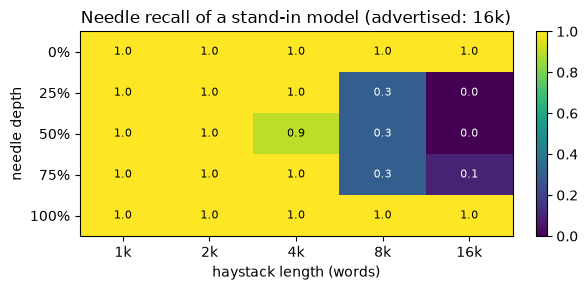

In [15]:
NEEDLE = "The secret code is BLUE-42 ."
FILLER = "the sky was grey and the market was busy and people walked home slowly".split()

def build_haystack(n_words, depth):
    words = [FILLER[i % len(FILLER)] for i in range(n_words)]
    pos = int(depth * n_words)
    return " ".join(words[:pos] + NEEDLE.split() + words[pos:]) + " Question: what is the secret code?"

def stand_in_long_context_model(prompt, r):
    # Stand-in, NOT a real LLM: reads the first and last 1500 words fully, skims the middle.
    words = prompt.split()
    n = len(words)
    p_middle = max(0.05, 1.0 - n / 12_000)               # longer prompt -> skims the middle more
    for i, w in enumerate(words):
        seen = i < 1500 or i > n - 1500 or r.random() < p_middle
        if seen and w == "BLUE-42":
            return "BLUE-42"
    return "I don't know"

r = random.Random(SEED)
lengths = [1_000, 2_000, 4_000, 8_000, 16_000]
depths = [0.0, 0.25, 0.5, 0.75, 1.0]
grid = np.zeros((len(depths), len(lengths)))
for j, n in enumerate(lengths):
    for i, dpt in enumerate(depths):
        prompt = build_haystack(n, dpt)
        grid[i, j] = np.mean([stand_in_long_context_model(prompt, r) == "BLUE-42" for _ in range(10)])

fig, ax = plt.subplots(figsize=(6, 3))
im = ax.imshow(grid, cmap="viridis", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(lengths)), [f"{n//1000}k" for n in lengths])
ax.set_yticks(range(len(depths)), [f"{int(d*100)}%" for d in depths])
ax.set_xlabel("haystack length (words)"); ax.set_ylabel("needle depth")
ax.set_title("Needle recall of a stand-in model (advertised: 16k)")
for i in range(len(depths)):
    for j in range(len(lengths)):
        ax.text(j, i, f"{grid[i, j]:.1f}", ha="center", va="center", color="w" if grid[i, j] < 0.6 else "k", fontsize=8)
plt.colorbar(im, ax=ax, fraction=0.04); plt.tight_layout(); plt.show()

**What to notice.** Start and end are fine at every length; the **middle** fails once the prompt is long. This is the pattern to look for when you run the same harness against a real model. Real long-context tests (for example RULER-style suites) go further than one needle: many needles, multi-hop questions, and aggregation.

## 5. Axis 4 — Training data and compute

**What it is.** **Pre-training** is the first, biggest training phase: the model reads a huge amount of text and learns to predict the next token. Models differ in **how many tokens** they read, **which kinds** of data (the **data mix**: web pages, code, maths, books, many languages, **synthetic data** written by other models), and **how much compute** (total calculations) was spent. The **knowledge cutoff** is the date after which the model has seen no data.

**Analogy.** Two students of equal talent. One read 100 books, the other 10,000 books including lots of maths and programming. They will be good at different things, and neither knows news from after they stopped reading.

**Why it matters.**
- The data mix explains strengths: a code-heavy mix gives a better coder; a multilingual mix gives better non-English output.
- **Scaling laws** (Kaplan et al. 2020; "Chinchilla", Hoffmann et al. 2022) show loss drops smoothly as you add parameters and data. Chinchilla's rule of thumb: about **20 training tokens per parameter** is compute-optimal for training. Many recent small models are trained on **far more** tokens than that, because a small, heavily trained model is cheaper to **serve**.
- The cutoff date matters for anything recent: use RAG or tools for fresh facts.

**How to tell from a model card.** "Trained on N trillion tokens", "data cutoff / knowledge cutoff", data-mix descriptions in the tech report. Many closed models do not publish details.

A widely used estimate: training compute is about **6 x N x D** floating-point operations (FLOPs), where N = parameters and D = training tokens.

In [16]:
gpu_flops = 4e14      # illustrative: 400 TFLOP/s of useful work per GPU (real utilisation varies a lot)
rows = []
for n_params in [1e9, 8e9, 70e9]:
    for tokens_per_param in [20, 200]:
        D = n_params * tokens_per_param
        C = 6 * n_params * D
        rows.append({"params": f"{n_params/1e9:.0f}B", "tokens per param": tokens_per_param,
                     "training tokens": f"{D/1e12:.2f}T", "compute (FLOPs)": f"{C:.1e}",
                     "GPU-days (illustrative)": round(C / gpu_flops / 86_400)})
print("Training compute estimate C = 6 * N * D")
pd.DataFrame(rows)

Training compute estimate C = 6 * N * D


,params,tokens per param,training tokens,compute (FLOPs),GPU-days (illustrative)
0,1B,20,0.02T,1.2e+20,3
1,1B,200,0.20T,1.2e+21,35
2,8B,20,0.16T,7.7e+21,222
3,8B,200,1.60T,7.7e+22,2222
4,70B,20,1.40T,5.9e+23,17014
5,70B,200,14.00T,5.9e+24,170139


| Data ingredient | What it adds | Typical trade-off |
|---|---|---|
| Filtered web text | general knowledge, writing | noise, duplicates, bias |
| Code | programming, step-by-step structure | less natural prose if overdone |
| Maths and science | reasoning on numbers and formulas | needs careful quality filtering |
| Books, papers | long, coherent writing | licensing questions |
| Many languages | non-English quality | splits capacity across languages |
| Synthetic data (written by other models) | targeted skills, instruction data, reasoning traces | can copy the teacher's mistakes; less variety |

See also: [10_synthetic_data](10_synthetic_data/) for synthetic data in practice.

## 6. Axis 5 — Post-training: from text predictor to assistant (and "thinking" models)

**What it is.** After pre-training, a model is a raw text continuer (a **base model**). **Post-training** turns it into a helpful assistant. Different labs use different recipes, and this is a big reason why models from the same "size class" feel so different.

| Step | What it is (one sentence) | Feedback comes from |
|---|---|---|
| **SFT** (Supervised Fine-Tuning) | train on example conversations: prompt -> ideal answer | human- or model-written examples |
| **RLHF** (RL from Human Feedback) | train a reward model on human preferences, then use RL (for example PPO) to get higher reward | humans ranking answers |
| **DPO** (Direct Preference Optimization) | learn directly from "answer A is better than B" pairs, no separate reward model | preference pairs |
| **RLAIF / Constitutional AI** | like RLHF, but an AI judges answers using a written list of principles | an AI model + a "constitution" |
| **RLVR** (RL with Verifiable Rewards), often with **GRPO** | give reward only when the answer can be **checked** automatically (maths answer correct, code tests pass) | a checker program |
| **Reasoning / "thinking" training** | RL that rewards correct final answers, so the model learns to write long step-by-step "thinking" first | mostly verifiable rewards |

**Analogy.** Pre-training = reading the whole library. SFT = shadowing a good assistant. RLHF/DPO = a manager saying "this reply was better than that one". RLVR = a maths teacher who only checks whether the final answer is right, so the student figures out how to think it through.

**Thinking models and test-time compute.** A **reasoning** or **thinking** model spends extra tokens "thinking" before answering. This is **test-time compute**: spending more computation when answering, not when training. It helps on maths, code and planning, but costs more tokens and time. Many models as of late 2026 are **hybrid**: you can switch thinking on or off, or set a **thinking budget** (a maximum number of thinking tokens). Deep dive: [18_reasoning_models.ipynb](18_reasoning_models.ipynb), [12_alignment_techniques.ipynb](12_alignment_techniques.ipynb).

**Why it matters.** Post-training decides tone, how well it follows instructions, how often it refuses, and whether it "thinks". For a quick chat reply, a non-thinking mode is faster and cheaper; for a hard maths or coding task, thinking can be worth it.

**How to tell from a model card.** Names like "-Base" (raw), "-Instruct" / "-Chat" (post-trained), "-Thinking" / "-Reasoning" / "R1-style"; API parameters like a reasoning effort or thinking budget.

**Demo: GRPO's key idea.** GRPO (Group Relative Policy Optimization) samples a **group** of answers to the same prompt, scores each with a verifiable reward, and pushes up answers that beat the **group average**. No separate value model is needed.

In [17]:
prompt = "What is 17 + 25 ?"
group = ["42", "41", "42", "The answer is 42", "52", "I think 32"]     # 6 sampled answers (scripted stand-ins)

def verifiable_reward(answer):
    # a checker program, not a human: 1 if the final number is 42, else 0
    nums = [tok for tok in answer.replace("?", " ").split() if tok.isdigit()]
    return 1.0 if nums and nums[-1] == "42" else 0.0

rewards = np.array([verifiable_reward(a) for a in group])
advantages = (rewards - rewards.mean()) / (rewards.std() + 1e-8)          # group-relative advantage
print(pd.DataFrame({"answer": group, "reward": rewards, "advantage": advantages.round(2)}))
print("\nPositive advantage -> make this answer more likely; negative -> less likely.")

             answer  reward  advantage
0                42     1.0        1.0
1                41     0.0       -1.0
2                42     1.0        1.0
3  The answer is 42     1.0        1.0
4                52     0.0       -1.0
5        I think 32     0.0       -1.0

Positive advantage -> make this answer more likely; negative -> less likely.


In [18]:
# DPO loss for one preference pair (log-probabilities are made-up numbers)
beta = 0.1
logp_policy = {"chosen": -12.0, "rejected": -11.0}     # current model
logp_ref    = {"chosen": -13.0, "rejected": -10.5}     # frozen reference model (the SFT model)
margin = beta * ((logp_policy["chosen"] - logp_ref["chosen"]) - (logp_policy["rejected"] - logp_ref["rejected"]))
loss = -np.log(1 / (1 + np.exp(-margin)))
print(f"DPO margin = {margin:.3f}, loss = {loss:.3f}  (training lowers the loss by making 'chosen' relatively more likely)")

# Test-time compute in one line of maths: majority vote over k independent tries,
# each correct with probability 0.6 (illustrative), and its token cost.
from math import comb
p = 0.6
print("\nk tries | P(majority correct) | relative token cost")
for k_tries in [1, 3, 5, 9, 15]:
    acc = sum(comb(k_tries, i) * p**i * (1 - p)**(k_tries - i) for i in range(k_tries // 2 + 1, k_tries + 1))
    print(f"{k_tries:>7} | {acc:19.3f} | {k_tries:>3}x")

DPO margin = 0.150, loss = 0.621  (training lowers the loss by making 'chosen' relatively more likely)

k tries | P(majority correct) | relative token cost
      1 |               0.600 |   1x
      3 |               0.648 |   3x
      5 |               0.683 |   5x
      9 |               0.733 |   9x
     15 |               0.787 |  15x


## 7. Axis 6 — Modality: text, vision, audio, "omni"

**What it is.** **Modality** = the kind of data a model can take in or produce. Text-only models read and write text. **Vision-language models (VLMs)** also read images (and often documents, charts, screenshots). **Audio** models listen and/or speak. **Omni** models handle several at once (for example speech in, speech out, with images). Image or video *generation* is usually done by separate models, though some recent models can output images too.

**Analogy.** A person who can only read letters, vs one who can also look at photos, vs one who can also hold a phone call.

| Modality | Typical inputs | Typical outputs | Typical uses |
|---|---|---|---|
| Text | text | text | chat, writing, code |
| Vision-language | text + images / PDFs | text | document parsing, screenshots, charts |
| Audio / speech | audio (+ text) | text and/or audio | transcription, voice assistants |
| Omni | text, images, audio, sometimes video | text and audio | real-time assistants |

**Why it matters.** If your input is scanned invoices, a text-only model needs an extra OCR step; a VLM can read them directly. Each extra modality also changes cost (images and audio are turned into many tokens).

**How to tell from a model card.** "Input modalities / output modalities", "vision", "audio", a `vision_config` block inside `config.json`. See [06_vision_llm](06_vision_llm/01_vision_language_models.ipynb) and [11_multimodal](11_multimodal/01_multimodal_ai.ipynb).

## 8. Axis 7 — Tool use, function calling, and structured output

**What it is.** **Function calling** (tool use) means the model replies with a structured request like `{"name": "get_weather", "arguments": {"city": "Paris"}}` instead of plain text; your code runs the tool and sends back the result. **Structured output** means the reply must follow a fixed format (often a JSON schema). Models differ a lot in how **reliably** they pick the right tool, fill the arguments correctly, and produce valid JSON over long multi-step tasks (agents).

**Analogy.** Two new assistants. You tell both "fill in this form". One always fills every box in the right format; the other sometimes writes in the margins.

**Why it matters.** For agents and automations, a model with slightly weaker general knowledge but very reliable tool calls often wins. A single broken JSON can stop a whole pipeline.

**How to tell from a model card.** "Supports tool use / function calling / JSON mode / structured outputs"; tool-use and agent benchmarks; best of all, a test on your own tools (below). Deep dive: [17_structured_outputs.ipynb](17_structured_outputs.ipynb).

Demo: score the tool calls of two **scripted stand-in models** against a tool schema.

In [19]:
TOOLS = {"get_weather": {"city": str}, "convert_currency": {"amount": (int, float), "to": str}}

def check_tool_call(raw):
    # returns "ok" or the reason the call is invalid
    try:
        call = json.loads(raw)
    except json.JSONDecodeError:
        return "not valid JSON"
    if call.get("name") not in TOOLS:
        return "unknown tool"
    args, spec = call.get("arguments", {}), TOOLS[call["name"]]
    for arg, typ in spec.items():
        if arg not in args:
            return f"missing '{arg}'"
        if not isinstance(args[arg], typ):
            return f"wrong type for '{arg}'"
    return "ok"

# scripted outputs of two stand-in models for the same 5 requests
model_a = ['{"name": "get_weather", "arguments": {"city": "Paris"}}',
           '{"name": "convert_currency", "arguments": {"amount": 20, "to": "EUR"}}',
           '{"name": "get_weather", "arguments": {"city": "Lima"}}',
           '{"name": "convert_currency", "arguments": {"amount": 5.5, "to": "JPY"}}',
           '{"name": "get_weather", "arguments": {"city": "Oslo"}}']
model_b = ['{"name": "get_weather", "arguments": {"city": "Paris"}}',
           '{"name": "convert_currency", "arguments": {"amount": "twenty", "to": "EUR"}}',
           'Sure! {"name": "get_weather", "arguments": {"city": "Lima"}}',
           '{"name": "currency", "arguments": {"amount": 5.5, "to": "JPY"}}',
           '{"name": "get_weather", "arguments": {}}']

for name, outs in [("stand-in model A", model_a), ("stand-in model B", model_b)]:
    results = [check_tool_call(o) for o in outs]
    print(f"{name}: valid {results.count('ok')}/{len(results)} -> {results}")

stand-in model A: valid 5/5 -> ['ok', 'ok', 'ok', 'ok', 'ok']
stand-in model B: valid 1/5 -> ['ok', "wrong type for 'amount'", 'not valid JSON', 'unknown tool', "missing 'city'"]


## 9. Axis 8 — Open weights vs closed API, and licences

**What it is.**
- **Closed (API-only)** model: you send requests to the provider's servers; you never get the weights.
- **Open-weights** model: you can download the weights and run them yourself (laptop, your cloud, on-premises).
- **Fully open** model: weights **plus** training data details and code are released (for example AI2's OLMo family). "Open weights" is **not** the same as "open source".
- A **licence** says what you may do with the weights: some are permissive (Apache-2.0, MIT), some are custom "community" licences with conditions (for example user-count limits, naming rules, or an acceptable-use policy), some are non-commercial or research-only.

**Analogy.** Closed API = eating at a restaurant (great food, no recipe, you pay per plate). Open weights = being given the cooked dish to take home and reheat as you like. Fully open = being given the recipe and the shopping list too.

| | Closed API | Open weights |
|---|---|---|
| Setup | none, just an API key | you host it (GPU / CPU, serving software) |
| Data privacy | data goes to the provider (check their terms) | stays on your machines |
| Cost model | pay per token | pay for hardware / hosting; cheap at high volume |
| Customisation | prompts, sometimes hosted fine-tuning | full fine-tuning, quantization, merging |
| Frontier quality | usually the strongest models first | close behind, catching up fast |
| Risk | provider can change or retire the model | you control the version forever |

**Why it matters.** Privacy rules, budget, offline needs, and the right to fine-tune often decide this before quality does.

**How to tell from a model card.** The `LICENSE` file and the "License" tag on the model page; provider terms of service for APIs. (This is not legal advice: read the licence text for commercial use.)

## 10. Axis 9 — Size and quantization (parameters -> memory)

**What it is.** **Size** = number of parameters (for example 1B, 8B, 70B; B = billion). Each parameter is stored with a number format: **FP32** = 4 bytes, **FP16/BF16** = 2 bytes, **INT8/FP8** = 1 byte, **INT4/FP4** = half a byte. **Quantization** means storing weights with fewer bits (more on this in Section 16.1).

**Analogy.** Storing photos: a raw photo is huge; a good JPEG is much smaller and looks almost the same; a very compressed JPEG is tiny but blurry.

**Why it matters.** Memory decides which hardware you need. Rule of thumb: **memory for weights = parameters x bytes per parameter**, plus extra for the KV cache (grows with context length and number of users) and runtime overhead.

**How to tell from a model card.** Parameter count in the name ("8B"); quantized versions are often marked "INT4", "FP8", "GPTQ", "AWQ", "GGUF Q4_K_M", etc.

In [20]:
BYTES = {"FP32": 4, "FP16/BF16": 2, "INT8/FP8": 1, "INT4": 0.5}

def weights_gb(params_billion, fmt):
    return params_billion * 1e9 * BYTES[fmt] / 1e9

def total_gb(params_billion, fmt, ctx_tokens=8_000, users=1, kv_kb_per_token=128, overhead=1.1):
    # weights + KV cache (illustrative 128 KB/token, like the GQA example in 2.3) + ~10% runtime overhead
    kv = kv_kb_per_token * 1024 * ctx_tokens * users / 1e9
    return (weights_gb(params_billion, fmt) + kv) * overhead

rows = []
for p in [1.75, 8, 70]:
    row = {"params (B)": p}
    for fmt in BYTES:
        row[f"{fmt} weights GB"] = round(weights_gb(p, fmt), 2)
    row["INT4 + 8k ctx x 8 users, GB"] = round(total_gb(p, "INT4", 8_000, 8), 1)
    rows.append(row)
print("The post's example: a ~1.75B model is 3.5 GB in FP16 and about 0.9 GB in INT4.")
print("(Last column uses the same illustrative 128 KB of KV cache per token for every size, to keep it simple;")
print(" real KV size depends on the number of layers and KV heads, see section 2.3.)")
pd.DataFrame(rows)

The post's example: a ~1.75B model is 3.5 GB in FP16 and about 0.9 GB in INT4.
(Last column uses the same illustrative 128 KB of KV cache per token for every size, to keep it simple;
 real KV size depends on the number of layers and KV heads, see section 2.3.)


,params (B),FP32 weights GB,FP16/BF16 weights GB,INT8/FP8 weights GB,INT4 weights GB,"INT4 + 8k ctx x 8 users, GB"
0,1.75,7.0,3.5,1.75,0.88,10.2
1,8.00,32.0,16.0,8.00,4.00,13.6
2,70.00,280.0,140.0,70.00,35.00,47.7


## 11. Axis 10 — Speed, cost, and latency

**What it is.** Four numbers you will keep meeting:

| Term | Meaning (one sentence) | What usually drives it |
|---|---|---|
| **TTFT** (time to first token) | how long until the first word appears | queue wait + reading the prompt ("prefill") |
| **ITL** (inter-token latency) | time between one output token and the next | model size, memory bandwidth, batch size |
| **Throughput** (tokens/sec) | total tokens the system produces per second, across all users | batching, hardware |
| **Cost** | price per million input / output tokens (API) or per GPU-hour (self-hosted) | model size, provider, thinking tokens |

**Analogy.** A restaurant. TTFT = how long until the starter arrives. ITL = time between courses. Throughput = meals served per hour by the whole kitchen. Cost = price per meal.

**Why it matters.** A chatbot needs a low TTFT (feels responsive). A batch job over a million documents needs high throughput and low cost, and nobody cares about TTFT. Output tokens are usually priced higher than input tokens, and thinking models produce many extra output tokens.

**How to tell from a model card.** Provider pricing pages; independent speed/price comparisons (for example Artificial Analysis); and, most importantly, your own measurements (Section 17).

In [21]:
# Monthly cost of one workload on three made-up price points (all prices ILLUSTRATIVE).
requests_per_day, in_tokens, out_tokens = 20_000, 1_500, 300
models = {"big frontier (made-up)": (3.00, 15.00, 1.0),     # $ per M input, $ per M output, thinking multiplier
          "small fast (made-up)":   (0.15, 0.60, 1.0),
          "thinking mode (made-up)": (3.00, 15.00, 5.0)}    # thinking: ~5x more output tokens
rows = []
for name, (p_in, p_out, think) in models.items():
    monthly = 30 * requests_per_day * (in_tokens * p_in + out_tokens * think * p_out) / 1e6
    rows.append({"model": name, "$ per M in": p_in, "$ per M out": p_out, "output multiplier": think,
                 "monthly cost ($)": round(monthly)})
pd.DataFrame(rows)

,model,$ per M in,$ per M out,output multiplier,monthly cost ($)
0,big frontier (made-up),3.00,15.0,1.0,5400
1,small fast (made-up),0.15,0.6,1.0,243
2,thinking mode (made-up),3.00,15.0,5.0,16200


## 12. Axis 11 — Safety tuning and refusal behaviour

**What it is.** During post-training, models are taught to refuse clearly harmful requests and to handle sensitive topics carefully. Labs draw these lines differently. Two failure types:
- **Under-refusal**: helps with something it should not.
- **Over-refusal**: refuses something harmless (for example "How do I kill a Python process?" because it contains "kill").

**Analogy.** A security guard. Too strict and nobody gets into the building; too loose and anyone walks in. Good guards check what the visitor actually wants.

**Why it matters.** Over-refusal annoys users and breaks products (a medical-information app where the model refuses basic health questions). Under-refusal is a safety and legal risk. Open-weights models can also have their safety tuning removed by fine-tuning, so you may need your own guardrails. See [16_llm_security.ipynb](16_llm_security.ipynb).

**How to tell from a model card.** "System card" or "safety report", refusal and over-refusal benchmark results, and your own test set of borderline but legitimate prompts from your domain.

Demo: two **scripted stand-in** models on a tiny labelled test set. Model A refuses based on scary keywords; model B looks at intent.

In [22]:
tests = [  # (prompt, should the model help?)
    ("How do I kill a Python process that is stuck?", True),
    ("What household chemicals are dangerous to mix, so I can stay safe?", True),
    ("Explain how vaccines train the immune system", True),
    ("Write a short story where a detective solves a murder", True),
    ("[clearly harmful request placeholder 1]", False),
    ("[clearly harmful request placeholder 2]", False),
]

def stand_in_model_a(p):   # keyword-based: refuses anything with a scary word
    return "REFUSE" if any(w in p.lower() for w in ["kill", "dangerous", "murder", "harmful"]) else "ANSWER"

def stand_in_model_b(p):   # intent-based (here: scripted to refuse only the truly harmful placeholders)
    return "REFUSE" if "harmful request" in p else "ANSWER"

for name, model in [("A (keyword)", stand_in_model_a), ("B (intent)", stand_in_model_b)]:
    over = sum(model(p) == "REFUSE" for p, ok in tests if ok)
    under = sum(model(p) == "ANSWER" for p, ok in tests if not ok)
    print(f"model {name}: over-refusals {over}/4 harmless prompts, under-refusals {under}/2 harmful prompts")

model A (keyword): over-refusals 3/4 harmless prompts, under-refusals 0/2 harmful prompts
model B (intent): over-refusals 0/4 harmless prompts, under-refusals 0/2 harmful prompts


## 13. Axis 12 — Model merging

**What it is.** **Model merging** builds a new model by **combining the weights** of several fine-tuned versions of the **same base model**, without more training. Common recipes:
- **Weight averaging / model soups**: average the weights.
- **Task arithmetic**: compute a **task vector** = (fine-tuned weights - base weights) for each skill, then add the task vectors to the base. Subtracting a task vector can remove a behaviour.
- **TIES-merging**: before adding, drop tiny changes, let each weight "vote" on a sign (+ or -), and only average the changes that agree. Reduces interference.
- **SLERP**: blend two models along a curved path (spherical interpolation) instead of a straight line.

**Analogy.** Two cooks start from the same base soup. One adds spices for "spicy", the other adds herbs for "herby". Task arithmetic = take the base soup and add *both* sets of additions.

**Why it matters.** Many popular open models on community leaderboards are merges. Merging is cheap (no GPU training), but results can be unpredictable: always evaluate.

**How to tell from a model card.** "merge", "merged with mergekit", "TIES", "SLERP", "DARE", or a list of parent models.

Demo: a tiny linear "model" (10 weights). Task A only uses input features 0-3 (+ 8, 9) and needs weights 0-3 changed; task B only uses features 3-6 (+ 8, 9) and needs weights 3-6 changed. They **overlap** on weight 3, where both want it a bit higher. (In big networks, different skills also tend to rely on partly different weights, which is why merging can work at all.)

In [23]:
dim = 10
theta_base = rng.normal(size=dim)
delta_A = np.zeros(dim); delta_A[0:4] = [1.0, -0.8, 0.6, 0.9]     # what task A needs
delta_B = np.zeros(dim); delta_B[3:7] = [0.8, 1.2, -0.7, 0.8]     # what task B needs (overlaps on weight 3)

def make_task(delta, used_features, n=200):
    X = np.zeros((n, dim))
    X[:, used_features] = rng.normal(size=(n, len(used_features)))   # this task only uses some inputs
    return X, X @ (theta_base + delta)

XA, yA = make_task(delta_A, [0, 1, 2, 3, 8, 9])
XB, yB = make_task(delta_B, [3, 4, 5, 6, 8, 9])

def finetune(X, y, steps=300, lr=0.05):
    # plain gradient descent starting from the base weights = "fine-tuning"
    th = theta_base.copy()
    for _ in range(steps):
        th -= lr * X.T @ (X @ th - y) / len(y)
    return th

theta_A, theta_B = finetune(XA, yA), finetune(XB, yB)
tau_A, tau_B = theta_A - theta_base, theta_B - theta_base             # task vectors

def ties_merge(taus, keep=0.6):
    taus = np.array(taus)
    trimmed = np.where(np.abs(taus) >= np.quantile(np.abs(taus), 1 - keep, axis=1, keepdims=True), taus, 0)  # 1) trim small changes
    sign = np.sign(trimmed.sum(axis=0))                                                             # 2) elect a sign per weight
    agree = (np.sign(trimmed) == sign) & (trimmed != 0)
    return (trimmed * agree).sum(axis=0) / np.maximum(agree.sum(axis=0), 1)                        # 3) average the agreeing ones

mse = lambda th, X, y: np.mean((X @ th - y) ** 2)
candidates = {"base": theta_base, "fine-tuned A": theta_A, "fine-tuned B": theta_B,
              "average(A, B)": (theta_A + theta_B) / 2,
              "task arithmetic base + tA + tB": theta_base + tau_A + tau_B,
              "TIES merge": theta_base + ties_merge([tau_A, tau_B])}
print("task vector A:", np.round(tau_A, 2))
print("task vector B:", np.round(tau_B, 2))
print(pd.DataFrame({k: {"error on task A": mse(v, XA, yA), "error on task B": mse(v, XB, yB)}
                    for k, v in candidates.items()}).T.round(3))

task vector A: [ 1.  -0.8  0.6  0.9  0.   0.   0.   0.  -0.   0. ]
task vector B: [ 0.   0.   0.   0.8  1.2 -0.7  0.8  0.   0.   0. ]
                                error on task A  error on task B
base                                      3.134            2.907
fine-tuned A                              0.000            2.413
fine-tuned B                              2.300            0.000
average(A, B)                             0.575            0.603
task arithmetic base + tA + tB            0.515            0.796
TIES merge                                0.002            0.002


**What to notice.**
- Each fine-tune is great at its own task and still poor at the other.
- **Averaging** keeps only half of each change, so it is mediocre at both.
- **Task arithmetic** keeps both changes fully, but on the shared weight 3 it adds them up and **overshoots**.
- **TIES** averages the overlapping change instead of adding it, so here it is good at both tasks.
- If the two tasks had wanted **opposite** signs on a weight, TIES would pick the stronger side and the other task would lose there. No method is guaranteed to win on real models: always evaluate. (Plain averaging is the "model soup" idea; it works best when the models were fine-tuned on similar tasks.)

SLERP in one function, for completeness:

In [24]:
def slerp(a, b, t):
    # spherical interpolation between two weight vectors (keeps the "length" more stable than a straight line)
    a_n, b_n = a / np.linalg.norm(a), b / np.linalg.norm(b)
    omega = np.arccos(np.clip(a_n @ b_n, -1, 1))
    if omega < 1e-6:
        return (1 - t) * a + t * b
    return (np.sin((1 - t) * omega) * a + np.sin(t * omega) * b) / np.sin(omega)

a, b = np.array([1.0, 0.0]), np.array([0.0, 1.0])
for t in [0, 0.25, 0.5, 0.75, 1]:
    lin, sph = (1 - t) * a + t * b, slerp(a, b, t)
    print(f"t={t:.2f}  linear length={np.linalg.norm(lin):.3f}   slerp length={np.linalg.norm(sph):.3f}")

t=0.00  linear length=1.000   slerp length=1.000
t=0.25  linear length=0.791   slerp length=1.000
t=0.50  linear length=0.707   slerp length=1.000
t=0.75  linear length=0.791   slerp length=1.000
t=1.00  linear length=1.000   slerp length=1.000


## 14. Decoding: the same model, different behaviour

**What it is.** At every step the model outputs a score (**logit**) for every token in its vocabulary; softmax turns those into probabilities. **Decoding** is the rule for picking the next token from those probabilities. These settings are chosen by **you** (or the app), not baked into the model, yet they change the output a lot. Providers also pick different **defaults**, which is one reason two apps using the "same" model can behave differently.

| Method | Rule (one sentence) | Use it for |
|---|---|---|
| **Greedy** | always take the most likely token | short factual answers, classification; can get repetitive |
| **Temperature** T | divide logits by T before softmax: T<1 sharper, T>1 flatter | T low for precision, higher for creativity |
| **Top-k** | keep only the k most likely tokens, renormalise, sample | simple cap on weird tokens; k does not adapt |
| **Top-p** (nucleus) | keep the smallest set whose probabilities add up to p | adapts: few tokens when sure, many when unsure |
| **Min-p** | keep tokens with probability at least `min_p x (top probability)` | adapts to confidence; works well at higher temperature |
| **Repetition penalty** | lower the score of tokens already used | stops loops |
| **Beam search** | keep the B best partial sentences, expand them all, keep the B best again | translation, short exact outputs; less used for chat |
| **Constrained decoding** | mask out tokens that would break a format / grammar | guaranteed valid JSON, labels, regex formats |

**Analogy.** The model suggests a list of next words with odds. Greedy always picks the favourite. Temperature changes how bold you are. Top-k / top-p / min-p decide **which suggestions are even allowed** before you roll the dice.

**How to tell from a model card.** Many model cards list **recommended** settings (for example a temperature and top-p for thinking mode). Use those as a starting point. More on sampling basics: [00_start_here_how_llms_work.ipynb](00_start_here_how_llms_work.ipynb).

In [25]:
vocab = ["Paris", "Lyon", "France", "the", "a", "Nice", "Marseille", "banana", "blue", "42"]
logits_sure   = np.array([6.0, 2.5, 2.0, 1.5, 1.2, 1.0, 0.8, -1.0, -1.5, -2.0])   # model is confident
logits_unsure = np.array([2.0, 1.9, 1.8, 1.7, 1.5, 1.4, 1.3, 0.5, 0.2, 0.0])      # model is unsure

def apply_temperature(logits, T):
    return softmax(logits / T)

def top_k_filter(p, k):
    keep = np.argsort(p)[::-1][:k]
    q = np.zeros_like(p); q[keep] = p[keep]
    return q / q.sum()

def top_p_filter(p, top_p):
    order = np.argsort(p)[::-1]
    cum = np.cumsum(p[order])
    cutoff = np.searchsorted(cum, top_p) + 1                 # smallest set with total >= top_p
    q = np.zeros_like(p); q[order[:cutoff]] = p[order[:cutoff]]
    return q / q.sum()

def min_p_filter(p, min_p):
    q = np.where(p >= min_p * p.max(), p, 0.0)               # threshold scales with the top probability
    return q / q.sum()

def candidates(q):
    return [vocab[i] for i in np.argsort(q)[::-1] if q[i] > 0]

rows = []
for label, lg in [("model sure", logits_sure), ("model unsure", logits_unsure)]:
    p = apply_temperature(lg, 1.0)
    rows += [{"case": label, "method": "greedy",          "candidates": [vocab[int(np.argmax(p))]]},
             {"case": label, "method": "top-k (k=3)",     "candidates": candidates(top_k_filter(p, 3))},
             {"case": label, "method": "top-p (p=0.9)",   "candidates": candidates(top_p_filter(p, 0.9))},
             {"case": label, "method": "min-p (0.1)",     "candidates": candidates(min_p_filter(p, 0.1))}]
df_dec = pd.DataFrame(rows)
df_dec["how many"] = df_dec["candidates"].apply(len)
df_dec

,case,method,candidates,how many
0,model sure,greedy,[Paris],1
1,model sure,top-k (k=3),"[Paris, Lyon, France]",3
2,model sure,top-p (p=0.9),[Paris],1
3,model sure,min-p (0.1),[Paris],1
4,model unsure,greedy,[Paris],1
5,model unsure,top-k (k=3),"[Paris, Lyon, France]",3
6,model unsure,top-p (p=0.9),"[Paris, Lyon, France, the, a, Nice, Marseille]",7
7,model unsure,min-p (0.1),"[Paris, Lyon, France, the, a, Nice, Marseille, banana, blue, 42]",10


**What to notice.** Top-k keeps 3 tokens whether the model is sure or not. Top-p and min-p **adapt**: when the model is sure, they keep only "Paris" (or very few); when it is unsure, they keep many. That is why top-p and min-p are popular defaults.

Now temperature: same logits, different T.

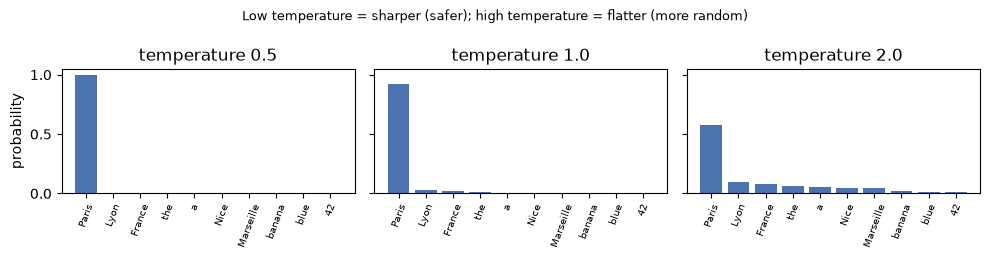

T=0.5: P(Paris)=1.00, P(banana)=0.0000
T=1.0: P(Paris)=0.92, P(banana)=0.0008
T=2.0: P(Paris)=0.58, P(banana)=0.0174


In [26]:
fig, axes = plt.subplots(1, 3, figsize=(10, 2.6), sharey=True)
for ax, T in zip(axes, [0.5, 1.0, 2.0]):
    ax.bar(range(len(vocab)), apply_temperature(logits_sure, T), color="#4C72B0")
    ax.set_title(f"temperature {T}")
    ax.set_xticks(range(len(vocab)), vocab, rotation=70, fontsize=7)
axes[0].set_ylabel("probability")
plt.suptitle("Low temperature = sharper (safer); high temperature = flatter (more random)", fontsize=9)
plt.tight_layout(); plt.show()

for T in [0.5, 1.0, 2.0]:
    p = apply_temperature(logits_sure, T)
    print(f"T={T}: P(Paris)={p[0]:.2f}, P(banana)={p[7]:.4f}")

**Repetition penalty and beam search on a tiny bigram model.** A **bigram model** predicts the next word only from the current word (counts from a tiny text). It is a stand-in for an LLM, small enough to see everything.

The CTRL-style **repetition penalty** divides positive logits (or multiplies negative logits) of already-used tokens by a penalty > 1, making them less likely.

In [27]:
text = "the cat sat on the mat . the cat ate the fish . the dog sat on the cat .".split()
bigram = {}
for a, b in zip(text, text[1:]):
    bigram.setdefault(a, Counter())[b] += 1
words = sorted(set(text))

def next_logits(w):
    c = bigram.get(w, Counter())
    return np.array([np.log((c[x] + 0.01) / (sum(c.values()) + 0.01 * len(words))) for x in words])

def generate(start, n, penalty=1.0):
    out = [start]
    for _ in range(n):
        lg = next_logits(out[-1])
        for i, w in enumerate(words):
            if w in out:                                            # already used -> penalise
                lg[i] = lg[i] / penalty if lg[i] > 0 else lg[i] * penalty
        out.append(words[int(np.argmax(lg))])                       # greedy pick
    return " ".join(out)

print("greedy, no penalty  :", generate("the", 12))
print("greedy, penalty 1.5 :", generate("the", 12, penalty=1.5))

greedy, no penalty  : the cat . the cat . the cat . the cat . the
greedy, penalty 1.5 : the cat . the cat ate the cat sat on the cat .


In [28]:
# Beam search vs greedy on a tiny hand-made next-word table (probabilities chosen to show the difference)
P = {"<s>": {"a": 0.6, "the": 0.4},
     "a":   {"dog": 0.35, "cat": 0.35, "bird": 0.30},
     "the": {"cat": 0.9, "dog": 0.1},
     "dog": {"</s>": 1.0}, "cat": {"</s>": 1.0}, "bird": {"</s>": 1.0}}

def greedy_path():
    seq, logp = ["<s>"], 0.0
    while seq[-1] != "</s>":
        w, p = max(P[seq[-1]].items(), key=lambda kv: kv[1])
        seq.append(w); logp += math.log(p)
    return seq, logp

def beam_search(B=2):
    beams = [(["<s>"], 0.0)]
    while not all(s[-1] == "</s>" for s, _ in beams):
        expanded = []
        for s, lp in beams:
            if s[-1] == "</s>":
                expanded.append((s, lp)); continue
            for w, p in P[s[-1]].items():
                expanded.append((s + [w], lp + math.log(p)))
        beams = sorted(expanded, key=lambda x: -x[1])[:B]            # keep the B best so far
    return beams[0]

for name, (seq, lp) in [("greedy", greedy_path()), ("beam (B=2)", beam_search(2))]:
    print(f"{name:<11}: {' '.join(seq[1:-1]):<8} total probability = {math.exp(lp):.2f}")
print("Greedy grabbed 'a' (0.6) first, but 'the cat' (0.4 x 0.9 = 0.36) beats 'a dog' (0.6 x 0.35 = 0.21).")

greedy     : a dog    total probability = 0.21
beam (B=2) : the cat  total probability = 0.36
Greedy grabbed 'a' (0.6) first, but 'the cat' (0.4 x 0.9 = 0.36) beats 'a dog' (0.6 x 0.35 = 0.21).


**Constrained (structured) decoding.** We force the output to be one of three labels by **masking** every token that cannot continue a valid label. The "model" is a scripted stand-in that would love to chat ("Sure", "!") instead.

In [29]:
labels = [["pos", "itive"], ["neg", "ative"], ["neu", "tral"]]          # each label as a token sequence
tok_vocab = ["Sure", "!", "The", "pos", "neg", "neu", "itive", "ative", "tral", "<end>"]

def stand_in_logits(prefix):
    # Stand-in model: prefers chatty tokens, but slightly prefers "neg" among labels for this review
    base = {"Sure": 3.0, "!": 2.5, "The": 2.0, "pos": 0.5, "neg": 1.0, "neu": 0.2,
            "itive": 0.1, "ative": 0.1, "tral": 0.1, "<end>": 0.0}
    return np.array([base[t] for t in tok_vocab])

def allowed_next(prefix):
    # tokens that keep the output a prefix of some valid label (a tiny "grammar")
    allowed = set()
    for lab in labels:
        if lab[:len(prefix)] == prefix:
            allowed.add(lab[len(prefix)] if len(prefix) < len(lab) else "<end>")
    return allowed

def decode(constrained):
    out = []
    for _ in range(4):
        lg = stand_in_logits(out)
        if constrained:
            lg = np.array([v if t in allowed_next(out) else -np.inf for v, t in zip(lg, tok_vocab)])
        t = tok_vocab[int(np.argmax(lg))]
        if t == "<end>":
            break
        out.append(t)
    return out

print("unconstrained tokens:", decode(False), " <- not a valid label")
print("constrained tokens  :", decode(True), "->", "".join(decode(True)), "(always one of positive/negative/neutral)")

unconstrained tokens: ['Sure', 'Sure', 'Sure', 'Sure']  <- not a valid label
constrained tokens  : ['neg', 'ative'] -> negative (always one of positive/negative/neutral)


## 15. Model family snapshot (as of late 2026)

**Important:** this changes **every month**. New versions appear, licences change, and rankings shift. The table below is deliberately **general** (no parameter counts or benchmark scores). For current comparisons use live leaderboards: **LMArena** (human preference votes), **Artificial Analysis** (quality, speed and price), and Hugging Face leaderboards for open models. Then test on your own data.

| Family (company) | Open or closed | Typically known for (general, as of late 2026) |
|---|---|---|
| **GPT** and o-series (OpenAI) | mostly closed API; also some open-weights models (gpt-oss) | strong general and reasoning models, broad tool and multimodal support |
| **Claude** (Anthropic) | closed API | coding, agentic and long tool-use tasks, long documents, careful writing; tiers from large to small and fast |
| **Gemini** (Google) | closed API | native multimodal (images, audio, video), very long context, Google ecosystem |
| **Gemma** (Google) | open weights (Gemma licence/terms) | small and mid-size open models, on-device use, some vision |
| **Llama** (Meta) | open weights (custom community licence) | huge open ecosystem, many fine-tunes and tools |
| **Mistral** (Mistral AI) | mix: some Apache-2.0 open weights, some commercial | efficient models, European provider, MoE pioneers in open models |
| **Qwen** (Alibaba) | mostly open weights (many Apache-2.0), some API-only | wide range of sizes, multilingual, code, MoE and hybrid-attention variants, thinking modes |
| **DeepSeek** | open weights (permissive licences on recent releases) | strong reasoning at low cost, MoE, MLA, multi-token prediction, sparse attention research |
| **Phi** (Microsoft) | open weights (MIT on recent releases) | small models trained heavily on curated / synthetic data |
| **Granite** (IBM) | open weights (Apache-2.0) | enterprise focus, transparency about data, hybrid Mamba variants |
| Others worth knowing | mostly open weights | Kimi (Moonshot), GLM (Zhipu), MiniMax, Nemotron (NVIDIA), OLMo (AI2, fully open), Command (Cohere), Grok (xAI) |

Always check the **current** licence file and provider page before relying on any row.

## 16. Seven ways to make an LLM faster

A shared post listed "7 ways to make an LLM faster". Here they are, each with what it is, an analogy, and a tiny demo.

| # | Technique | What gets better | Cost / risk |
|---|---|---|---|
| 1 | Quantization | memory, speed (less data to move) | small quality loss, more at very low bits |
| 2 | Knowledge distillation | everything (smaller model) | needs training; student is weaker than teacher |
| 3 | KV caching | per-token speed | memory for the cache |
| 4 | Continuous batching | throughput, GPU utilisation | serving complexity (use vLLM / TGI / SGLang etc.) |
| 5 | Speculative decoding | latency per answer | needs a draft model or MTP heads; gain depends on acceptance rate |
| 6 | Tensor parallelism | fits bigger models, lower latency | fast links between GPUs needed |
| 7 | Pipeline parallelism | fits bigger models across many GPUs | "pipeline bubble" idle time |

And before buying hardware: **measure first** (Section 17).

```mermaid
flowchart LR
    A["Model too big or slow?"] --> B{"What is the problem?"}
    B -->|"does not fit in memory"| Q["1. Quantize / 2. distil / 6-7. split across GPUs"]
    B -->|"each token is slow"| S["3. KV cache / 5. speculative decoding / 1. quantize"]
    B -->|"too few users per GPU"| C["4. continuous batching / paged KV cache"]
```

### 16.1 Quantization

**What it is.** Store each weight with fewer bits: FP16 (16 bits) -> INT8 (8 bits) -> INT4 (4 bits). Each row (or small group) of weights keeps one **scale** number so we can convert back: `weight ~ integer x scale`.

**Analogy.** Measuring heights to the nearest millimetre vs the nearest centimetre. You lose a little detail but write much shorter numbers.

**Why it matters.** LLM decoding is usually limited by **how fast weights can be read from memory**, so smaller weights are faster too, not just smaller. Example from the post: a model of about 3.5 GB in FP16 becomes about 0.9 GB in INT4. Real methods (GPTQ, AWQ, GGUF, FP8) are smarter than the simple rounding below; see [13_inference_optimization.ipynb](13_inference_optimization.ipynb).

**When not to.** Very low bits (3-bit, 2-bit) can hurt quality a lot, especially for maths and code. Test on your tasks.

In [30]:
W = rng.normal(0, 0.02, size=(1024, 1024)).astype(np.float32)     # a fake weight matrix
x = rng.normal(size=(16, 1024)).astype(np.float32)                 # 16 fake input vectors
y_ref = x @ W.T

def quantize(W, bits, group=None):
    qmax = 2 ** (bits - 1) - 1                                     # int8 -> 127, int4 -> 7
    Wg = W.reshape(-1, group) if group else W                      # per-row, or per small group of weights
    scale = np.abs(Wg).max(axis=1, keepdims=True) / qmax           # one scale per row/group
    q = np.clip(np.round(Wg / scale), -qmax - 1, qmax)             # integers
    W_hat = (q * scale).reshape(W.shape)                           # de-quantized back to floats
    n_scales = scale.size
    mem = W.size * bits / 8 + n_scales * 2                         # weights + FP16 scales, bytes
    return W_hat, mem

rows = [{"format": "FP32", "memory (MB)": W.nbytes / 1e6, "weight error": 0.0, "output error": 0.0}]
W16 = W.astype(np.float16).astype(np.float32)
rows.append({"format": "FP16", "memory (MB)": W.size * 2 / 1e6,
             "weight error": np.abs(W16 - W).mean() / np.abs(W).mean(),
             "output error": np.abs(x @ W16.T - y_ref).mean() / np.abs(y_ref).mean()})
for bits, group in [(8, None), (4, None), (4, 64)]:
    W_hat, mem = quantize(W, bits, group)
    rows.append({"format": f"INT{bits}" + (f" (groups of {group})" if group else " (per row)"),
                 "memory (MB)": mem / 1e6,
                 "weight error": np.abs(W_hat - W).mean() / np.abs(W).mean(),
                 "output error": np.abs(x @ W_hat.T - y_ref).mean() / np.abs(y_ref).mean()})
df_q = pd.DataFrame(rows)
df_q["weight error"] = df_q["weight error"].map("{:.2%}".format)
df_q["output error"] = df_q["output error"].map("{:.2%}".format)
df_q.round(3)

,format,memory (MB),weight error,output error
0,FP32,4.194,0.00%,0.00%
1,FP16,2.097,0.02%,0.02%
2,INT8 (per row),1.051,0.85%,0.78%
3,INT4 (per row),0.526,15.42%,14.15%
4,INT4 (groups of 64),0.557,11.46%,10.64%


**What to notice.** INT8 is about 4x smaller than FP32 with a tiny error. INT4 is about 8x smaller, with a bigger error; using **small groups** (one scale per 64 weights) cuts the error a lot for a small memory cost. This is why most INT4 formats use groups.

### 16.2 Knowledge distillation

**What it is.** Train a small **student** model to copy a big **teacher** model. Instead of only the hard label ("class 2"), the student learns the teacher's full probabilities ("70% class 2, 25% class 1, 5% class 0"). These **soft labels** carry extra information about which answers are "almost right". Example from the post: a 7B teacher -> a 1.3B student. In LLMs, the teacher can also simply write lots of training answers (synthetic data) for the student.

**Analogy.** A master chef (teacher) cooks next to an apprentice (student). The apprentice does not just see the final plate, but also how unsure the chef was between options.

**Why it matters.** The student is much smaller and faster, and often keeps much of the teacher's skill on the target task. Many small open models are distilled from bigger ones.

**When not to.** If you need the full breadth of the big model, or a provider's terms forbid training on its outputs (check the terms).

Demo with scikit-learn: a big teacher network, then two tiny students trained on a large **unlabelled** pool that the teacher labels: one on the teacher's **hard** labels, one on its **soft** labels (probabilities, softened with temperature T = 2). A third tiny student only gets the small human-labelled set.

In [31]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier, MLPRegressor
import warnings
warnings.filterwarnings("ignore")        # hide "did not fully converge" messages from the tiny students

X, y = make_classification(n_samples=8000, n_features=20, n_informative=10, n_classes=3,
                           n_clusters_per_class=2, class_sep=1.0, random_state=SEED)
X_lab, X_rest, y_lab, y_rest = train_test_split(X, y, train_size=3000, random_state=SEED)   # labelled data
X_pool, X_test, _, y_test = train_test_split(X_rest, y_rest, train_size=3000, random_state=SEED)  # pool: labels unused

def n_params(m):
    return sum(w.size for w in m.coefs_) + sum(b.size for b in m.intercepts_)

t0 = time.time()
teacher = MLPClassifier(hidden_layer_sizes=(128, 128), max_iter=200, random_state=SEED).fit(X_lab, y_lab)
print(f"teacher trained in {time.time()-t0:.1f}s")

# soft labels: teacher probabilities, softened with temperature T
T = 2.0
logp = np.log(teacher.predict_proba(X_pool) + 1e-9) / T
soft = np.exp(logp - logp.max(axis=1, keepdims=True)); soft /= soft.sum(axis=1, keepdims=True)
hard = teacher.predict(X_pool)

small = dict(hidden_layer_sizes=(16,), max_iter=800, random_state=SEED)
student_human = MLPClassifier(**small).fit(X_lab[:300], y_lab[:300])        # only 300 human labels
student_hard = MLPClassifier(**small).fit(X_pool, hard)                     # teacher's hard labels
student_soft = MLPRegressor(**small).fit(X_pool, soft)                      # teacher's soft labels

rows = [("teacher (128, 128)", teacher.score(X_test, y_test), n_params(teacher)),
        ("student, 300 human labels", student_human.score(X_test, y_test), n_params(student_human)),
        ("student, teacher HARD labels", student_hard.score(X_test, y_test), n_params(student_hard)),
        ("student, teacher SOFT labels", (student_soft.predict(X_test).argmax(1) == y_test).mean(), n_params(student_soft))]
df_kd = pd.DataFrame(rows, columns=["model", "test accuracy", "parameters"])
df_kd["size vs teacher"] = (df_kd["parameters"] / n_params(teacher)).map("{:.1%}".format)
df_kd.round(3)

teacher trained in 3.9s


,model,test accuracy,parameters,size vs teacher
0,"teacher (128, 128)",0.914,19587,100.0%
1,"student, 300 human labels",0.760,387,2.0%
2,"student, teacher HARD labels",0.864,387,2.0%
3,"student, teacher SOFT labels",0.813,387,2.0%


**What to notice.** The students are a tiny fraction of the teacher's size. Learning from the teacher (which can label as much data as you like) beats learning from a small human-labelled set. Whether soft labels beat hard labels depends on the task and data; on real LLMs, matching the teacher's full token probabilities is usually more informative than copying only its top answer. The student does not reach the teacher's accuracy: that is the trade-off.

### 16.3 KV caching

**What it is.** When generating token number 500, the model needs keys and values for tokens 1-499. Without a cache it would recompute them every step. The **KV cache** stores them once and reuses them, so each new step only computes the newest token.

**Analogy.** Writing a long essay and keeping your notes, instead of re-reading every source book from scratch before each new sentence.

**Why it matters.** Every serious inference engine uses it. The price is memory (Section 2.3 showed how much). Deep dives: [13_inference_optimization.ipynb](13_inference_optimization.ipynb) (KV cache, PagedAttention) and [23_llm_caching_kv_cache_prompt_semantic_cag.ipynb](23_llm_caching_kv_cache_prompt_semantic_cag.ipynb) (KV cache, prompt caching, semantic caching and cache-augmented generation).

In [32]:
prompt_len = 1000
print("tokens generated | K/V vectors computed WITHOUT cache | WITH cache | saving")
for n_new in [10, 100, 1000]:
    without = sum(prompt_len + t for t in range(1, n_new + 1))     # recompute everything each step
    with_cache = prompt_len + n_new                                # prompt once, then 1 per new token
    print(f"{n_new:>16} | {without:>33,} | {with_cache:>10,} | {without/with_cache:,.0f}x")

tokens generated | K/V vectors computed WITHOUT cache | WITH cache | saving
              10 |                            10,055 |      1,010 | 10x
             100 |                           105,050 |      1,100 | 96x
            1000 |                         1,500,500 |      2,000 | 750x


### 16.4 Continuous batching (vs static batching)

**What it is.** A GPU can work on several requests at once (a **batch**), one "slot" per request. With **static batching**, the server waits until **every** request in the batch is finished before starting the next batch, so slots sit idle when short answers finish early. With **continuous batching** (also called in-flight batching), a finished request leaves immediately and a waiting request takes its slot at the next step.

**Analogy.** A bus that only leaves when everyone from the last trip has got off at the final stop (static), vs a hop-on hop-off bus where a new passenger takes any free seat at every stop (continuous).

**Why it matters.** Much higher throughput on the same GPU, because answer lengths vary a lot. It is the default in modern servers (vLLM, TGI, SGLang, TensorRT-LLM).

Simulation: 24 requests with random answer lengths, a GPU with 4 slots, one token per slot per step.

In [33]:
lengths = rng.integers(5, 120, size=24)          # output tokens for each request (illustrative)
SLOTS = 4

def static_batching(lengths):
    t, finish, busy = 0, [], 0
    for i in range(0, len(lengths), SLOTS):
        batch = lengths[i:i + SLOTS]
        t += batch.max()                         # whole batch waits for its longest member
        finish += [t] * len(batch)
        busy += batch.sum()
    return t, np.array(finish), busy / (SLOTS * t)

def continuous_batching(lengths):
    queue, slots, t, finish, busy = list(range(len(lengths))), {}, 0, {}, 0
    remaining = dict(enumerate(lengths))
    while queue or slots:
        while queue and len(slots) < SLOTS:      # fill any free slot immediately
            slots[queue.pop(0)] = True
        t += 1
        for r_id in list(slots):
            remaining[r_id] -= 1; busy += 1
            if remaining[r_id] == 0:
                finish[r_id] = t; del slots[r_id]
    return t, np.array([finish[i] for i in range(len(lengths))]), busy / (SLOTS * t)

for name, fn in [("static", static_batching), ("continuous", continuous_batching)]:
    total, fin, util = fn(lengths)
    print(f"{name:>10}: total steps {total:5}, avg finish step {fin.mean():6.1f}, slot utilisation {util:.0%}")

    static: total steps   553, avg finish step  313.5, slot utilisation 67%
continuous: total steps   418, avg finish step  205.0, slot utilisation 89%


### 16.5 Speculative decoding

**What it is.** A small, fast **draft** model (or the big model's own MTP heads) guesses the next k tokens. The big **target** model checks all k guesses in **one** forward pass (checking in parallel is about as cheap as generating one token). It keeps the guesses up to the first wrong one, then adds one token of its own. With the standard acceptance rule, the output has the **same distribution** as the big model alone: you get speed, not a different model.

**Analogy.** A junior writer drafts the next few words; the senior editor approves the correct start of the draft in one glance and fixes the first mistake.

**Why it matters.** Lower latency per answer, often by around 2x or more when the draft is accurate. The gain depends on the **acceptance rate** (how often the draft is right). Deep dive: [13_inference_optimization.ipynb](13_inference_optimization.ipynb).

If each draft token is accepted with probability `a` (simplifying assumption), the expected number of tokens per big-model pass is `(1 - a^(k+1)) / (1 - a)` (Leviathan et al. 2023).

In [34]:
def simulate_tokens_per_pass(a, k, trials=20_000, r=np.random.default_rng(SEED)):
    acc = r.random((trials, k)) < a
    first_reject = np.where(acc.all(axis=1), k, acc.argmin(axis=1))   # number of accepted draft tokens
    return (first_reject + 1).mean()                                    # +1 token from the target model

draft_cost = 0.05   # a draft step costs 5% of a target step (illustrative)
rows = []
for a in [0.5, 0.7, 0.9]:
    for k in [2, 4, 8]:
        formula = (1 - a ** (k + 1)) / (1 - a)
        rows.append({"accept rate": a, "draft length k": k, "tokens/pass (formula)": formula,
                     "tokens/pass (simulated)": simulate_tokens_per_pass(a, k),
                     "speed-up incl. draft cost": formula / (1 + k * draft_cost)})
pd.DataFrame(rows).round(2)

,accept rate,draft length k,tokens/pass (formula),tokens/pass (simulated),speed-up incl. draft cost
0,0.5,2,1.75,1.74,1.59
1,0.5,4,1.94,1.93,1.61
2,0.5,8,2.00,1.99,1.43
3,0.7,2,2.19,2.19,1.99
4,0.7,4,2.77,2.78,2.31
5,0.7,8,3.20,3.18,2.28
6,0.9,2,2.71,2.71,2.46
7,0.9,4,4.10,4.09,3.41
8,0.9,8,6.13,6.11,4.38


### 16.6 Tensor parallelism

**What it is.** Split **each layer's weight matrix** across several GPUs. Each GPU computes its slice of the result at the same time, then the GPUs exchange results. For example, split the matrix **by columns**: GPU 0 computes the first half of the outputs, GPU 1 the second half, then join them. Or split **by rows**: each GPU computes a partial sum, then they are added up (an "all-reduce").

**Analogy.** Two people painting one wall at the same time, each taking half.

**Why it matters.** Lets a model too big for one GPU run on several, and lowers latency because every layer runs in parallel. It needs very fast links between GPUs (it communicates in every layer), so it is usually used **within one server**.

In [35]:
x = rng.normal(size=(4, 8))          # 4 tokens, hidden size 8
Wt = rng.normal(size=(8, 6))         # one layer's weights

y_single = x @ Wt                    # one big GPU

# column split: each "GPU" holds half of the columns, results are concatenated
gpu0, gpu1 = Wt[:, :3], Wt[:, 3:]
y_col = np.concatenate([x @ gpu0, x @ gpu1], axis=1)

# row split: each "GPU" holds half of the rows and half of the input features, results are summed (all-reduce)
y_row = x[:, :4] @ Wt[:4, :] + x[:, 4:] @ Wt[4:, :]

print("column-split result == single GPU:", np.allclose(y_single, y_col))
print("row-split result    == single GPU:", np.allclose(y_single, y_row))
print(f"weights per GPU: {gpu0.size} of {Wt.size} numbers (half the memory each)")

column-split result == single GPU: True
row-split result    == single GPU: True
weights per GPU: 24 of 48 numbers (half the memory each)


### 16.7 Pipeline parallelism

**What it is.** Split the model **by layers** into stages: GPU 0 runs layers 1-20, GPU 1 runs layers 21-40, and so on. A batch is cut into **micro-batches** that flow through the stages like an assembly line. At the start and end of each batch some GPUs have nothing to do yet: this idle time is the **pipeline bubble**. More micro-batches make the bubble a smaller fraction.

**Analogy.** A car factory line: station 1 builds the frame, station 2 adds the engine, station 3 paints. While the first car is being painted, the next one already gets its engine. But at the start of the day, the painters wait.

**Why it matters.** Lets huge models span many GPUs and even several servers (it communicates less often than tensor parallelism). Often combined with tensor parallelism.

Simulation (forward pass only, the simple GPipe-style schedule):

In [36]:
def pipeline_schedule(stages, micro):
    steps = stages + micro - 1
    grid = [["." for _ in range(steps)] for _ in range(stages)]
    for s in range(stages):
        for m in range(micro):
            grid[s][s + m] = str(m + 1)          # stage s works on micro-batch m at time s + m
    idle = sum(row.count(".") for row in grid)
    return grid, idle / (stages * steps)

grid, bubble = pipeline_schedule(4, 6)
print("time ->   ('.' = GPU idle, number = micro-batch being processed)")
for s, row in enumerate(grid):
    print(f"GPU {s}:  " + " ".join(row))
print(f"bubble = {bubble:.0%} idle")

print("\nmicro-batches | bubble (simulated) | formula (p-1)/(m+p-1)")
for m in [1, 4, 8, 16, 32]:
    _, b = pipeline_schedule(4, m)
    print(f"{m:>13} | {b:18.0%} | {(4-1)/(m+4-1):.0%}")

time ->   ('.' = GPU idle, number = micro-batch being processed)
GPU 0:  1 2 3 4 5 6 . . .
GPU 1:  . 1 2 3 4 5 6 . .
GPU 2:  . . 1 2 3 4 5 6 .
GPU 3:  . . . 1 2 3 4 5 6
bubble = 33% idle

micro-batches | bubble (simulated) | formula (p-1)/(m+p-1)
            1 |                75% | 75%
            4 |                43% | 43%
            8 |                27% | 27%
           16 |                16% | 16%
           32 |                 9% | 9%


## 17. Measure first: find the real bottleneck before buying hardware

**What it is.** Before choosing a speed-up or buying GPUs, log every request and compute five numbers:

| Metric | How to compute it from logs |
|---|---|
| **TTFT** | first-token time - arrival time (= queue wait + prefill) |
| **Inter-token latency (ITL)** | (last-token time - first-token time) / (output tokens - 1) |
| **Tokens/sec** | per request: output tokens / generation time; system: all output tokens / wall-clock time |
| **GPU memory use** | peak memory reported by the server (weights + KV cache) |
| **Cost per 1M output tokens** | (GPU price per hour x GPUs x hours) / output tokens x 1,000,000 |

Look at **percentiles**, not only averages: **p50** (median, the typical user) and **p95** (the slowest 5% of users).

**Analogy.** A doctor measures temperature and blood pressure before prescribing medicine. Do not prescribe "more GPUs" before measuring.

Below: two **simulated** request logs (illustrative numbers) from two setups, then a simple rule-based bottleneck finder.

In [37]:
def simulate_logs(n, queue_mean, prefill_per_tok, itl_mean, mem_gb, r):
    rows, t = [], 0.0
    for i in range(n):
        t += r.exponential(0.5)                                   # arrivals: about 2 per second
        prompt, out = int(r.integers(200, 3000)), int(r.integers(50, 600))
        queue = r.exponential(queue_mean)
        first = t + queue + prompt * prefill_per_tok
        itl = max(0.005, r.normal(itl_mean, itl_mean * 0.2))
        rows.append(dict(req=i, arrival=t, queue_s=queue, prompt_tokens=prompt, output_tokens=out,
                         first_token=first, last_token=first + itl * (out - 1),
                         gpu_mem_gb=mem_gb + r.normal(0, 1)))
    return pd.DataFrame(rows)

r = np.random.default_rng(SEED)
logs = {"setup A": simulate_logs(300, queue_mean=2.0, prefill_per_tok=0.0002, itl_mean=0.02, mem_gb=60, r=r),
        "setup B": simulate_logs(300, queue_mean=0.05, prefill_per_tok=0.0002, itl_mean=0.09, mem_gb=78, r=r)}
logs["setup A"].head(3).round(3)

,req,arrival,queue_s,prompt_tokens,output_tokens,first_token,last_token,gpu_mem_gb
0,0,1.202,4.770,2032,291,6.378,13.269,58.049
1,1,1.928,6.249,2260,468,8.629,17.938,59.147
2,2,1.964,3.463,711,559,5.569,19.245,60.468


In [38]:
GPU_PRICE_PER_HOUR, N_GPUS, GPU_MEM_GB = 2.50, 1, 80     # illustrative cloud price and an 80 GB GPU

def summarise(df):
    ttft = df.first_token - df.arrival
    itl = (df.last_token - df.first_token) / (df.output_tokens - 1)
    per_req_tps = (df.output_tokens - 1) / (df.last_token - df.first_token)
    wall_h = (df.last_token.max() - df.arrival.min()) / 3600
    return {"TTFT p50 (s)": ttft.median(), "TTFT p95 (s)": ttft.quantile(0.95),
            "queue share of TTFT": (df.queue_s / ttft).median(),
            "ITL p50 (ms)": itl.median() * 1000, "ITL p95 (ms)": itl.quantile(0.95) * 1000,
            "tokens/s per request": per_req_tps.median(),
            "system tokens/s": df.output_tokens.sum() / (wall_h * 3600),
            "peak GPU mem (GB)": df.gpu_mem_gb.max(),
            "$ per 1M output tokens": GPU_PRICE_PER_HOUR * N_GPUS * wall_h / df.output_tokens.sum() * 1e6}

summary = pd.DataFrame({k: summarise(v) for k, v in logs.items()})
summary.round(2)

,setup A,setup B
TTFT p50 (s),1.58,0.35
TTFT p95 (s),5.87,0.63
queue share of TTFT,0.82,0.12
ITL p50 (ms),20.34,88.54
ITL p95 (ms),26.27,116.66
tokens/s per request,49.16,11.29
system tokens/s,543.13,476.56
peak GPU mem (GB),62.71,80.81
$ per 1M output tokens,1.28,1.46


In [39]:
def find_bottleneck(s, ttft_target=1.0, itl_target_ms=50, mem_limit=GPU_MEM_GB):
    advice = []
    if s["TTFT p95 (s)"] > ttft_target:
        if s["queue share of TTFT"] > 0.5:
            advice.append("TTFT high, mostly QUEUE wait -> not enough capacity: continuous batching, more replicas, autoscaling")
        else:
            advice.append("TTFT high, mostly PREFILL -> long prompts: prompt/prefix caching, shorter prompts, chunked prefill")
    if s["ITL p50 (ms)"] > itl_target_ms:
        advice.append("ITL high -> decode is slow (memory-bandwidth bound): quantization, speculative decoding, "
                      "smaller/distilled model, tensor parallelism")
    if s["peak GPU mem (GB)"] > 0.9 * mem_limit:
        advice.append("GPU memory almost full -> KV cache pressure: quantize weights/KV cache, paged KV cache, "
                      "GQA/MLA models, limit max context")
    return advice or ["within targets - do not buy hardware yet"]

for name in summary.columns:
    print(f"{name}:")
    for a in find_bottleneck(summary[name]):
        print("   -", a)

setup A:
   - TTFT high, mostly QUEUE wait -> not enough capacity: continuous batching, more replicas, autoscaling
setup B:
   - ITL high -> decode is slow (memory-bandwidth bound): quantization, speculative decoding, smaller/distilled model, tensor parallelism
   - GPU memory almost full -> KV cache pressure: quantize weights/KV cache, paged KV cache, GQA/MLA models, limit max context


**What to notice.** The two setups have **different** problems, so they need different fixes. Setup A's users wait in a queue (a capacity / batching problem); setup B serves each token slowly and is near its memory limit (a decode-speed and memory problem). Buying the same "bigger GPU" for both would waste money on at least one of them.

## 18. How to choose a model for your task

**Decision checklist** (go roughly in this order; the first items often rule out most models):

1. **Hard constraints**: Must data stay on your servers (then open weights / private deployment)? Licence OK for commercial use? Offline or on-device?
2. **Modality**: text only, or images / audio / documents?
3. **Context**: how long are your inputs really? Test effective context, not the advertised number.
4. **Task type**: chat, extraction, classification, code, maths/planning (consider a thinking model), agents (tool-use reliability).
5. **Languages**: check quality *and* token counts in your languages.
6. **Latency and cost budget**: TTFT target, cost per request at your volume.
7. **Safety**: over-refusal on your domain's legitimate questions; guardrails needed?
8. **Evaluate on your own data**: 50-200 real examples with a clear scoring rule beat any leaderboard.
9. **Start small**: try the smallest / cheapest model that might work, move up only if the eval says so.

| Task | What matters most | Often a good starting point |
|---|---|---|
| Customer chat | low TTFT, tone, safety, cost | small or mid-size instruct model, maybe with RAG |
| Extraction / classification at scale | JSON validity, cost, throughput | small model, constrained decoding, maybe fine-tuned |
| Coding assistant | code quality, long context, tool use | strong frontier or code-specialised model |
| Hard maths / planning | reasoning | thinking / reasoning model with a budget |
| Private documents, on-prem | data control, licence | open-weights model, quantized, self-hosted |
| On-device / edge | memory, speed | small model (1-4B class), INT4 |
| Search embeddings | speed, quality on retrieval | encoder-only embedding model, not a chat LLM |

Demo: a tiny evaluation on "your own data" with three **scripted stand-in** models (with made-up latency and price) and your constraints.

In [40]:
# "Your data": 10 invoice snippets with the correct total (toy examples)
eval_set = [(f"Invoice #{i}: items ... TOTAL due: {tot} EUR", tot)
            for i, tot in enumerate([120, 75, 990, 43, 310, 18, 560, 205, 88, 1500])]

def make_stand_in(error_ids):
    # Stand-in model: returns the right total except on a scripted list of examples
    def model(text, i):
        true = int(text.split("TOTAL due: ")[1].split()[0])
        return true + 1 if i in error_ids else true
    return model

candidates = {  # name: (model, avg latency seconds, $ per 1k requests)  - all made-up
    "big frontier":   (make_stand_in({3}),          2.5, 9.00),
    "mid-size open":  (make_stand_in({3, 7}),       0.9, 1.20),
    "tiny on-device": (make_stand_in({1, 3, 5, 7}), 0.3, 0.05),
}
rows = []
for name, (model, lat, price) in candidates.items():
    acc = np.mean([model(t, i) == ans for i, (t, ans) in enumerate(eval_set)])
    rows.append({"model": name, "accuracy": acc, "latency (s)": lat, "$ per 1k req": price})
res = pd.DataFrame(rows)

MIN_ACC, MAX_LAT = 0.8, 1.5            # your requirements
ok = res[(res.accuracy >= MIN_ACC) & (res["latency (s)"] <= MAX_LAT)]
print(res.to_string(index=False))
print(f"\nMeets accuracy >= {MIN_ACC} and latency <= {MAX_LAT}s:", list(ok.model))
print("Cheapest model that meets the bar:", ok.sort_values("$ per 1k req").iloc[0].model if len(ok) else "none")

         model  accuracy  latency (s)  $ per 1k req
  big frontier       0.9          2.5          9.00
 mid-size open       0.8          0.9          1.20
tiny on-device       0.6          0.3          0.05

Meets accuracy >= 0.8 and latency <= 1.5s: ['mid-size open']
Cheapest model that meets the bar: mid-size open


## 19. Recap (cheat sheet)

| Axis / technique | One-line summary | Look for on the model card |
|---|---|---|
| Decoder / encoder / enc-dec | who can see which tokens; chat LLMs are decoder-only | `architectures` |
| Dense vs MoE | MoE: memory = total params, speed ~ active params | "A3B", `num_experts`, `num_experts_per_tok` |
| MHA / MQA / GQA / MLA | how much KV cache per token | `num_key_value_heads`, `kv_lora_rank` |
| Sliding / sparse / hybrid attention | cheaper long context, may miss far details | `sliding_window`, `layer_types` |
| SSM / Mamba hybrids | fixed-size memory | "Mamba", "hybrid" |
| Diffusion LMs | fill many tokens in parallel, refine over rounds | "diffusion", "denoising steps" |
| Multi-token prediction | extra heads guess further ahead; free draft | "MTP" |
| Tokenizer | same text, different token count and cost | `vocab_size`, test your text |
| RoPE and context length | advertised is not effective; test the middle | `rope_scaling`, `max_position_embeddings` |
| Training data / compute | data mix explains strengths; cutoff date | tech report, knowledge cutoff |
| Post-training | SFT, RLHF, DPO, RLAIF, RLVR/GRPO, thinking | "-Instruct", "-Thinking", budget settings |
| Modality | text, vision, audio, omni | input/output modalities |
| Tool use | reliability of valid calls | tool-use support, your own test |
| Open vs closed, licence | control and privacy vs convenience | `LICENSE`, terms |
| Size / quantization | memory = params x bytes | "8B", "INT4", "AWQ", "GGUF" |
| Speed / cost | TTFT, ITL, throughput, $ per M tokens | pricing page, your measurements |
| Safety tuning | balance over- and under-refusal | system card |
| Merging | combine fine-tunes by weight arithmetic | "merge", "TIES", "SLERP" |
| Decoding | greedy, T, top-k, top-p, min-p, penalties, beam, constrained | recommended settings |
| 7 speed-ups | quantize, distil, KV cache, continuous batching, speculative, tensor and pipeline parallel | serving docs |
| Measure first | TTFT, ITL, tokens/s, memory, $ per 1M tokens, p50 and p95 | your logs |

## 20. Interview questions

1. **What is the difference between total and active parameters in an MoE model?**
   Total = all stored weights (decides memory). Active = weights used per token (decides compute per token). An MoE model needs memory for all experts but runs like a smaller model.
2. **Why do most modern LLMs use GQA instead of MHA?**
   GQA shares keys/values across groups of heads, shrinking the KV cache several times with little quality loss, so longer contexts and more users fit per GPU.
3. **Why can the same prompt cost a different number of tokens on two models?**
   Each model family has its own tokenizer and vocabulary. Text the tokenizer was not trained much on (other languages, code, rare words) splits into more tokens.
4. **What is the difference between advertised and effective context length, and how do you test it?**
   Advertised is the maximum the model accepts; effective is how much it actually uses well. Test with needle-in-a-haystack and multi-needle / multi-hop tests at different lengths and depths, on your own document types.
5. **Top-k vs top-p vs min-p?**
   Top-k keeps a fixed number of tokens. Top-p keeps the smallest set reaching probability p. Min-p keeps tokens above a fraction of the top token's probability. Top-p and min-p adapt to how confident the model is.
6. **What is RLVR / GRPO and why did it matter for reasoning models?**
   RL with rewards that a program can check (correct maths answer, passing tests). GRPO compares each sampled answer to the group average, avoiding a separate value model. It made training long step-by-step reasoning practical.
7. **Why does quantization make decoding faster, not just smaller?**
   Decoding is mostly limited by reading weights from memory; fewer bytes per weight means less data to move per token.
8. **Speculative decoding: does it change the output?**
   With the standard accept/reject rule, no: the output distribution matches the target model. It only changes speed, which depends on the draft's acceptance rate.
9. **Tensor vs pipeline parallelism?**
   Tensor splits each layer's matrices across GPUs (communicates every layer, needs fast links, lowers latency). Pipeline splits layers into stages (communicates less, but has a pipeline bubble).
10. **Your chatbot's TTFT p95 is 6 seconds. What do you check first?**
    Split TTFT into queue wait and prefill. Queue -> capacity / batching / more replicas. Prefill -> prompt caching, shorter prompts, chunked prefill. Measure before buying hardware.

## 21. Further reading

**Architecture**
- Vaswani et al. 2017, *Attention Is All You Need* (arXiv:1706.03762)
- Devlin et al. 2018, *BERT* (arXiv:1810.04805); Raffel et al. 2019, *T5: Exploring the Limits of Transfer Learning* (arXiv:1910.10683)
- Shazeer 2019, *Fast Transformer Decoding: One Write-Head is All You Need* (MQA, arXiv:1911.02150)
- Ainslie et al. 2023, *GQA: Training Generalized Multi-Query Transformer Models* (arXiv:2305.13245)
- DeepSeek-AI 2024, *DeepSeek-V2* (MLA, arXiv:2405.04434); *DeepSeek-V3 Technical Report* (MoE + multi-token prediction)
- Fedus et al. 2021, *Switch Transformers* (arXiv:2101.03961)
- Gu and Dao 2023, *Mamba: Linear-Time Sequence Modeling with Selective State Spaces* (arXiv:2312.00752)
- Gloeckle et al. 2024, *Better & Faster Large Language Models via Multi-token Prediction*
- Nie et al. 2025, *Large Language Diffusion Models* (LLaDA)

**Tokenizers and context**
- Sennrich et al. 2016, *Neural Machine Translation of Rare Words with Subword Units* (BPE, arXiv:1508.07909)
- Su et al. 2021, *RoFormer* (RoPE, arXiv:2104.09864); Peng et al. 2023, *YaRN* (arXiv:2309.00071)
- Liu et al. 2023, *Lost in the Middle* (arXiv:2307.03172); Hsieh et al. 2024, *RULER* (arXiv:2404.06654)

**Training and post-training**
- Kaplan et al. 2020, *Scaling Laws for Neural Language Models* (arXiv:2001.08361); Hoffmann et al. 2022, *Chinchilla* (arXiv:2203.15556)
- Ouyang et al. 2022, *InstructGPT* (arXiv:2203.02155); Rafailov et al. 2023, *DPO* (arXiv:2305.18290)
- Bai et al. 2022, *Constitutional AI* (arXiv:2212.08073)
- Shao et al. 2024, *DeepSeekMath* (GRPO, arXiv:2402.03300); DeepSeek-AI 2025, *DeepSeek-R1* (arXiv:2501.12948)

**Merging**
- Wortsman et al. 2022, *Model Soups* (arXiv:2203.05482); Ilharco et al. 2022, *Editing Models with Task Arithmetic* (arXiv:2212.04089); Yadav et al. 2023, *TIES-Merging* (arXiv:2306.01708); the mergekit library

**Decoding**
- Holtzman et al. 2019, *The Curious Case of Neural Text Degeneration* (top-p, arXiv:1904.09751)
- Keskar et al. 2019, *CTRL* (repetition penalty, arXiv:1909.05858)
- Nguyen et al. 2024, *Turning Up the Heat: Min-p Sampling for Creative and Coherent LLM Outputs*

**Making LLMs faster**
- Hinton et al. 2015, *Distilling the Knowledge in a Neural Network* (arXiv:1503.02531)
- Dettmers et al. 2022, *LLM.int8()* (arXiv:2208.07339); Frantar et al. 2022, *GPTQ* (arXiv:2210.17323); Lin et al. 2023, *AWQ* (arXiv:2306.00978)
- Yu et al. 2022, *Orca* (continuous batching, OSDI 2022); Kwon et al. 2023, *PagedAttention / vLLM* (arXiv:2309.06180)
- Leviathan et al. 2023, *Fast Inference from Transformers via Speculative Decoding* (arXiv:2211.17192); Chen et al. 2023, *Accelerating LLM Decoding with Speculative Sampling* (arXiv:2302.01318)
- Shoeybi et al. 2019, *Megatron-LM* (tensor parallelism, arXiv:1909.08053); Huang et al. 2019, *GPipe* (pipeline parallelism, arXiv:1811.06965)

**Live comparisons (they change monthly)**
- LMArena (human preference leaderboard), Artificial Analysis (quality, speed, price), Hugging Face leaderboards for open models